# Cost-Related Barriers to Care — BRFSS 2024
**Life cycle of Machine learning Project**

* Understanding the Problem Statement
* Data Collection
* Exploratory data analysis
* Data Cleaning
* Data Pre-Processing
* Model Training
* Choose best model

## 🗺️ Roadmap: read this first
**EDA (Exploratory Data Analysis)** = getting to know the data *before* building any model: what's in it, what's missing, and which factors seem related to the answer we want to predict.
EDA **does not change the data**. It produces *understanding* and *decisions* that are used in the feature engineering notebook.

```
 1 Problem ─► 2 Load data ─► 3 Feature types ─► 4 Category shares ─► 5 One feature at a time
                                                                              │
 ┌────────────────────────────────────────────────────────────────────────────┘
 ▼
 6 Which features relate to the target? ─► 7 Missing / Unknown ─► 8 The target itself
                                                                              │
 ┌────────────────────────────────────────────────────────────────────────────┘
 ▼
 9 Plot helper ─► 10 Factor by factor (13 factors) ─► 11 State picture ─► 12 Insurance × income ─► 13 Final report
```

| Step | Question it answers | Result |
|---|---|---|
| 1 | What problem are we solving? | Problem statement |
| 2 | What does the data look like? | 455,997 rows × 43 columns |
| 3 | Which columns are numeric, which are categorical? | All 35 predictors are categorical |
| 4 | How are answers spread across categories? | % per category |
| 5 | What does each feature look like on its own? | Bar charts |
| 6 | Which features are linked to the target, and how strongly? | Chi-square + Cramér's V ranking |
| 7 | How much information is missing? | % "Unknown" per feature |
| 8 | How common is the problem? | 9.5% (sample), 12.3% (U.S. adults) |
| 9 | (Tool) a reusable plotting function | `plot_factor()` |
| 10 | Does each factor change the risk? | 13 factor charts + reports |
| 11 | Do states differ? | State ranking |
| 12 | Do insurance and income work together? | Heat map |
| 13 | What did we learn, and what goes into the model? | Final report |

**Order logic:** first understand the problem (1) and the raw data (2–4); then look at each feature alone (5), then together with the target (6); check data quality (7); study the target (8); then answer "does this factor matter?" one factor at a time (9–12); finally summarise the decisions for modelling (13).

# STEP 1 · Understand the problem
> **What:** Describe the data source and state the problem we want to solve.  
> **Why here:** Every analysis starts with a clear question; otherwise we don't know what to look for.  
> **Result of this step:** the problem statement

### About
The Behavioral Risk Factor Surveillance System (BRFSS) is the CDC's state-based telephone survey of U.S. adults. It collects data on health-related risk behaviours, chronic conditions and use of preventive services.
One of its core questions asks whether, in the past 12 months, the respondent **needed to see a doctor but could not because of cost**.

### Problem statement

* Cost-related barriers to care delay diagnosis and treatment, and they are not spread evenly across the population.
* Public-health programmes (outreach, enrolment assistance, financial counselling) need to know **who** is most likely to face these barriers, so resources go where they matter.

**In this project we use the data to build a Classification model:**

* The model predicts whether an adult reports being unable to see a doctor because of cost in the past 12 months (`could_not_afford_doctor` = Yes/No).
* It identifies the demographic, socioeconomic, insurance, policy and health factors associated with this barrier, and checks whether the model works equally well across population groups.

# STEP 2 · Data collection and loading
> **What:** Describe the data source, import the libraries, load the CSV and take a first look (head, shape, summary, data types).  
> **Why here:** We need the problem (Step 1) first, so we know what to look for in the data.  
> **Result of this step:** **455,997 rows × 43 columns**

* Dataset source: CDC BRFSS 2024 public-use file (`LLCP2024XPT.zip`), prepared in `0_Data_Preparation_BRFSS2024.ipynb`.
* The analytic data has 455,997 rows (adults with a Yes/No answer to `MEDCOST1`) and 43 columns.
* **Survey weights:** BRFSS is not a simple random sample. Raw (unweighted) percentages describe the *sample*. Weighted percentages, using `survey_weight`, estimate the *U.S. adult population*. Both are shown below.

https://www.cdc.gov/brfss/annual_data/annual_2024.html

### 2a · Import Data and Required Packages

**Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

%matplotlib inline

**Import the CSV Data as Pandas DataFrame**

In [2]:
df = pd.read_csv(r"BRFSS2024_access.csv", dtype={"children_in_household": str})

**Show Top 5 Records**

In [3]:
df.head()

,seqno,could_not_afford_doctor,state,census_region,medicaid_expansion_state,urban_rural,age_group,sex,race_ethnicity,education,income,employment,marital_status,home_ownership,veteran,children_in_household,insurance_type,general_health,physical_unhealthy_days,mental_unhealthy_days,bmi_category,smoking_status,physical_activity,diabetes,heart_disease,stroke,copd,depression,kidney_disease,arthritis,asthma,cancer_non_skin,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty,has_personal_doctor,last_checkup,survey_weight,strata,psu
0,2024000001,No,Alabama,South,No,Urban,75-79,Female,White NH,High school graduate,Unknown,Retired,Widowed,Own,No,0,Medicare,Good,1-13 days,0 days,Normal,Never,Yes,No,No,No,No,No,No,Yes,Never,No,No,No,No,No,No,No,Yes,<1 yr,261.525511,11011,2024000001
1,2024000002,No,Alabama,South,No,Urban,80+,Male,White NH,College graduate,$200k+,Retired,Married,Own,Yes,0,Medicare,Excellent,0 days,0 days,Overweight,Former,Yes,No,Yes,No,No,No,No,Yes,Never,No,No,No,No,No,No,No,Yes,<1 yr,307.169688,11011,2024000002
2,2024000003,Yes,Alabama,South,No,Urban,55-59,Male,White NH,Some college/technical,Unknown,Employed for wages,Unmarried couple,Own,Yes,0,Employer/union,Very good,14+ days,0 days,Normal,Current daily,Yes,No,No,No,No,No,No,Yes,Never,No,No,No,No,No,No,No,No,5+ yrs,2939.862806,11011,2024000003
3,2024000004,No,Alabama,South,No,Urban,80+,Male,White NH,College graduate,$35k-<50k,Retired,Married,Own,No,0,Medicare,Excellent,0 days,0 days,Overweight,Never,Yes,No,No,No,No,No,No,Yes,Never,No,Yes,No,No,No,No,No,Yes,<1 yr,153.584844,11011,2024000004
4,2024000005,No,Alabama,South,No,Urban,45-49,Male,White NH,Some college/technical,$15k-<25k,Unable to work,Never married,Own,No,0,Medicaid/CHIP/State,Good,0 days,0 days,Normal,Never,No,No,No,No,No,No,No,No,Never,No,Yes,No,No,Yes,No,Yes,Yes,<1 yr,1229.623036,11011,2024000005


**Shape of the dataset**

In [4]:
df.shape

(455997, 43)

**Summary of the dataset**

In [5]:
# Display summary statistics for a dataframe
df.describe()

,seqno,survey_weight,strata,psu
count,4.559970e+05,455997.000000,455997.000000,4.559970e+05
mean,2.024007e+09,576.162706,310148.962936,2.024007e+09
std,7.485052e+03,1171.897467,159399.806088,7.485052e+03
min,2.024000e+09,0.012286,11011.000000,2.024000e+09
25%,2.024002e+09,106.574575,182111.000000,2.024002e+09
50%,2.024005e+09,263.631170,311171.000000,2.024005e+09
75%,2.024008e+09,581.354198,442011.000000,2.024008e+09
max,2.024044e+09,49582.191041,782022.000000,2.024044e+09


**Check Datatypes in the dataset**

In [6]:
# Check Null and Dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 455997 entries, 0 to 455996
Data columns (total 43 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   seqno                          455997 non-null  int64  
 1   could_not_afford_doctor        455997 non-null  str    
 2   state                          455997 non-null  str    
 3   census_region                  455997 non-null  str    
 4   medicaid_expansion_state       455997 non-null  str    
 5   urban_rural                    455997 non-null  str    
 6   age_group                      455997 non-null  str    
 7   sex                            455997 non-null  str    
 8   race_ethnicity                 455997 non-null  str    
 9   education                      455997 non-null  str    
 10  income                         455997 non-null  str    
 11  employment                     455997 non-null  str    
 12  marital_status                 455997 non

# STEP 3 · Identify feature types
> **What:** Separate numeric and categorical columns, and set aside ID and survey-design columns.  
> **Why here:** The type decides which charts and tests can be used in the next steps.  
> **Result of this step:** **35 categorical predictors + target**; no continuous features

In [7]:
# columns that are IDs / survey-design variables, not features
design_cols = ['seqno', 'survey_weight', 'strata', 'psu']
# define numerical & categorical columns
numeric_features = [f for f in df.select_dtypes(include='number').columns if f not in design_cols]
categorical_features = [f for f in df.select_dtypes(exclude='number').columns if f not in design_cols]

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 0 numerical features : []

We have 39 categorical features : ['could_not_afford_doctor', 'state', 'census_region', 'medicaid_expansion_state', 'urban_rural', 'age_group', 'sex', 'race_ethnicity', 'education', 'income', 'employment', 'marital_status', 'home_ownership', 'veteran', 'children_in_household', 'insurance_type', 'general_health', 'physical_unhealthy_days', 'mental_unhealthy_days', 'bmi_category', 'smoking_status', 'physical_activity', 'diabetes', 'heart_disease', 'stroke', 'copd', 'depression', 'kidney_disease', 'arthritis', 'asthma', 'cancer_non_skin', 'hearing_difficulty', 'vision_difficulty', 'cognitive_difficulty', 'mobility_difficulty', 'selfcare_difficulty', 'independent_living_difficulty', 'has_personal_doctor', 'last_checkup']


**Every predictor in BRFSS is categorical.** Questions have fixed answer options, and age and income are released in bands.
So, unlike the visa data, there are no continuous features to power-transform. In notebook 2 we'll *create* two numeric features (counts of chronic conditions and of disabilities).

# STEP 4 · How are answers spread across categories?
> **What:** The % of people in each category, for every feature.  
> **Why here:** A quick table check before drawing charts: it shows rare categories and large "Unknown" groups.  
> **Result of this step:** a % table per feature

In [8]:
# proportion of count data on categorical columns
for col in categorical_features:
    print(df[col].value_counts(normalize=True).round(4) * 100)
    print('---------------------------')

could_not_afford_doctor
No     90.49
Yes     9.51
Name: proportion, dtype: float64
---------------------------
state
New York                9.58
Washington              5.64
Minnesota               3.32
Maryland                3.16
Wisconsin               2.86
Florida                 2.86
Indiana                 2.85
Utah                    2.80
Nebraska                2.77
Texas                   2.69
Maine                   2.65
Illinois                2.62
Michigan                2.49
Colorado                2.38
Kansas                  2.38
Ohio                    2.23
Massachusetts           2.07
South Carolina          2.07
Iowa                    1.91
New Jersey              1.89
Arizona                 1.88
California              1.83
Kentucky                1.63
Missouri                1.60
Georgia                 1.58
Connecticut             1.58
Oklahoma                1.54
New Hampshire           1.53
Virginia                1.50
Montana                 1.49
Hawaii       

vision_difficulty
No         90.77
Yes         5.33
Unknown     3.90
Name: proportion, dtype: float64
---------------------------


cognitive_difficulty
No         83.86
Yes        11.70
Unknown     4.44
Name: proportion, dtype: float64
---------------------------
mobility_difficulty
No         79.99
Yes        15.57
Unknown     4.44
Name: proportion, dtype: float64
---------------------------
selfcare_difficulty
No         91.72
Unknown     4.40
Yes         3.88
Name: proportion, dtype: float64
---------------------------


independent_living_difficulty
No         87.58
Yes         7.63
Unknown     4.79
Name: proportion, dtype: float64
---------------------------
has_personal_doctor
Yes        86.81
No         12.22
Unknown     0.97
Name: proportion, dtype: float64
---------------------------
last_checkup
<1 yr      80.91
1-2 yrs     8.67
2-5 yrs     4.69
5+ yrs      4.01
Unknown     1.13
Never       0.60
Name: proportion, dtype: float64
---------------------------


**Insights**
 - `could_not_afford_doctor`: **9.5% Yes** in the sample, a 1:9.5 imbalance (much stronger than the visa data's 1:2).
 - `income` has the most non-response (**19.0% Unknown**). It is kept as its own category, because people who don't report income can differ systematically.
 - `insurance_type`: employer/union and Medicare are the largest groups; 5.5% report no coverage.
 - `state` has 53 levels (50 states minus Tennessee, + DC, Guam, Puerto Rico, Virgin Islands). Most of its signal is captured more compactly by `census_region` and `medicaid_expansion_state`.

# STEP 5 · Univariate analysis: one feature at a time
> **What:** A bar chart for each feature, showing how many people gave each answer.  
> **Why here:** Before comparing features with the target, we need to know what each one looks like on its own.  
> **Result of this step:** one bar chart per feature

* The term univariate analysis refers to the analysis of one variable prefix “uni” means “one.” The purpose of univariate analysis is to understand the distribution of values for a single variable.

Other Type of Analysis are
* **Bivariate Analysis:** The analysis of two variables.
* **Multivariate Analysis:** The analysis of two or more variables.

### Categorical Features

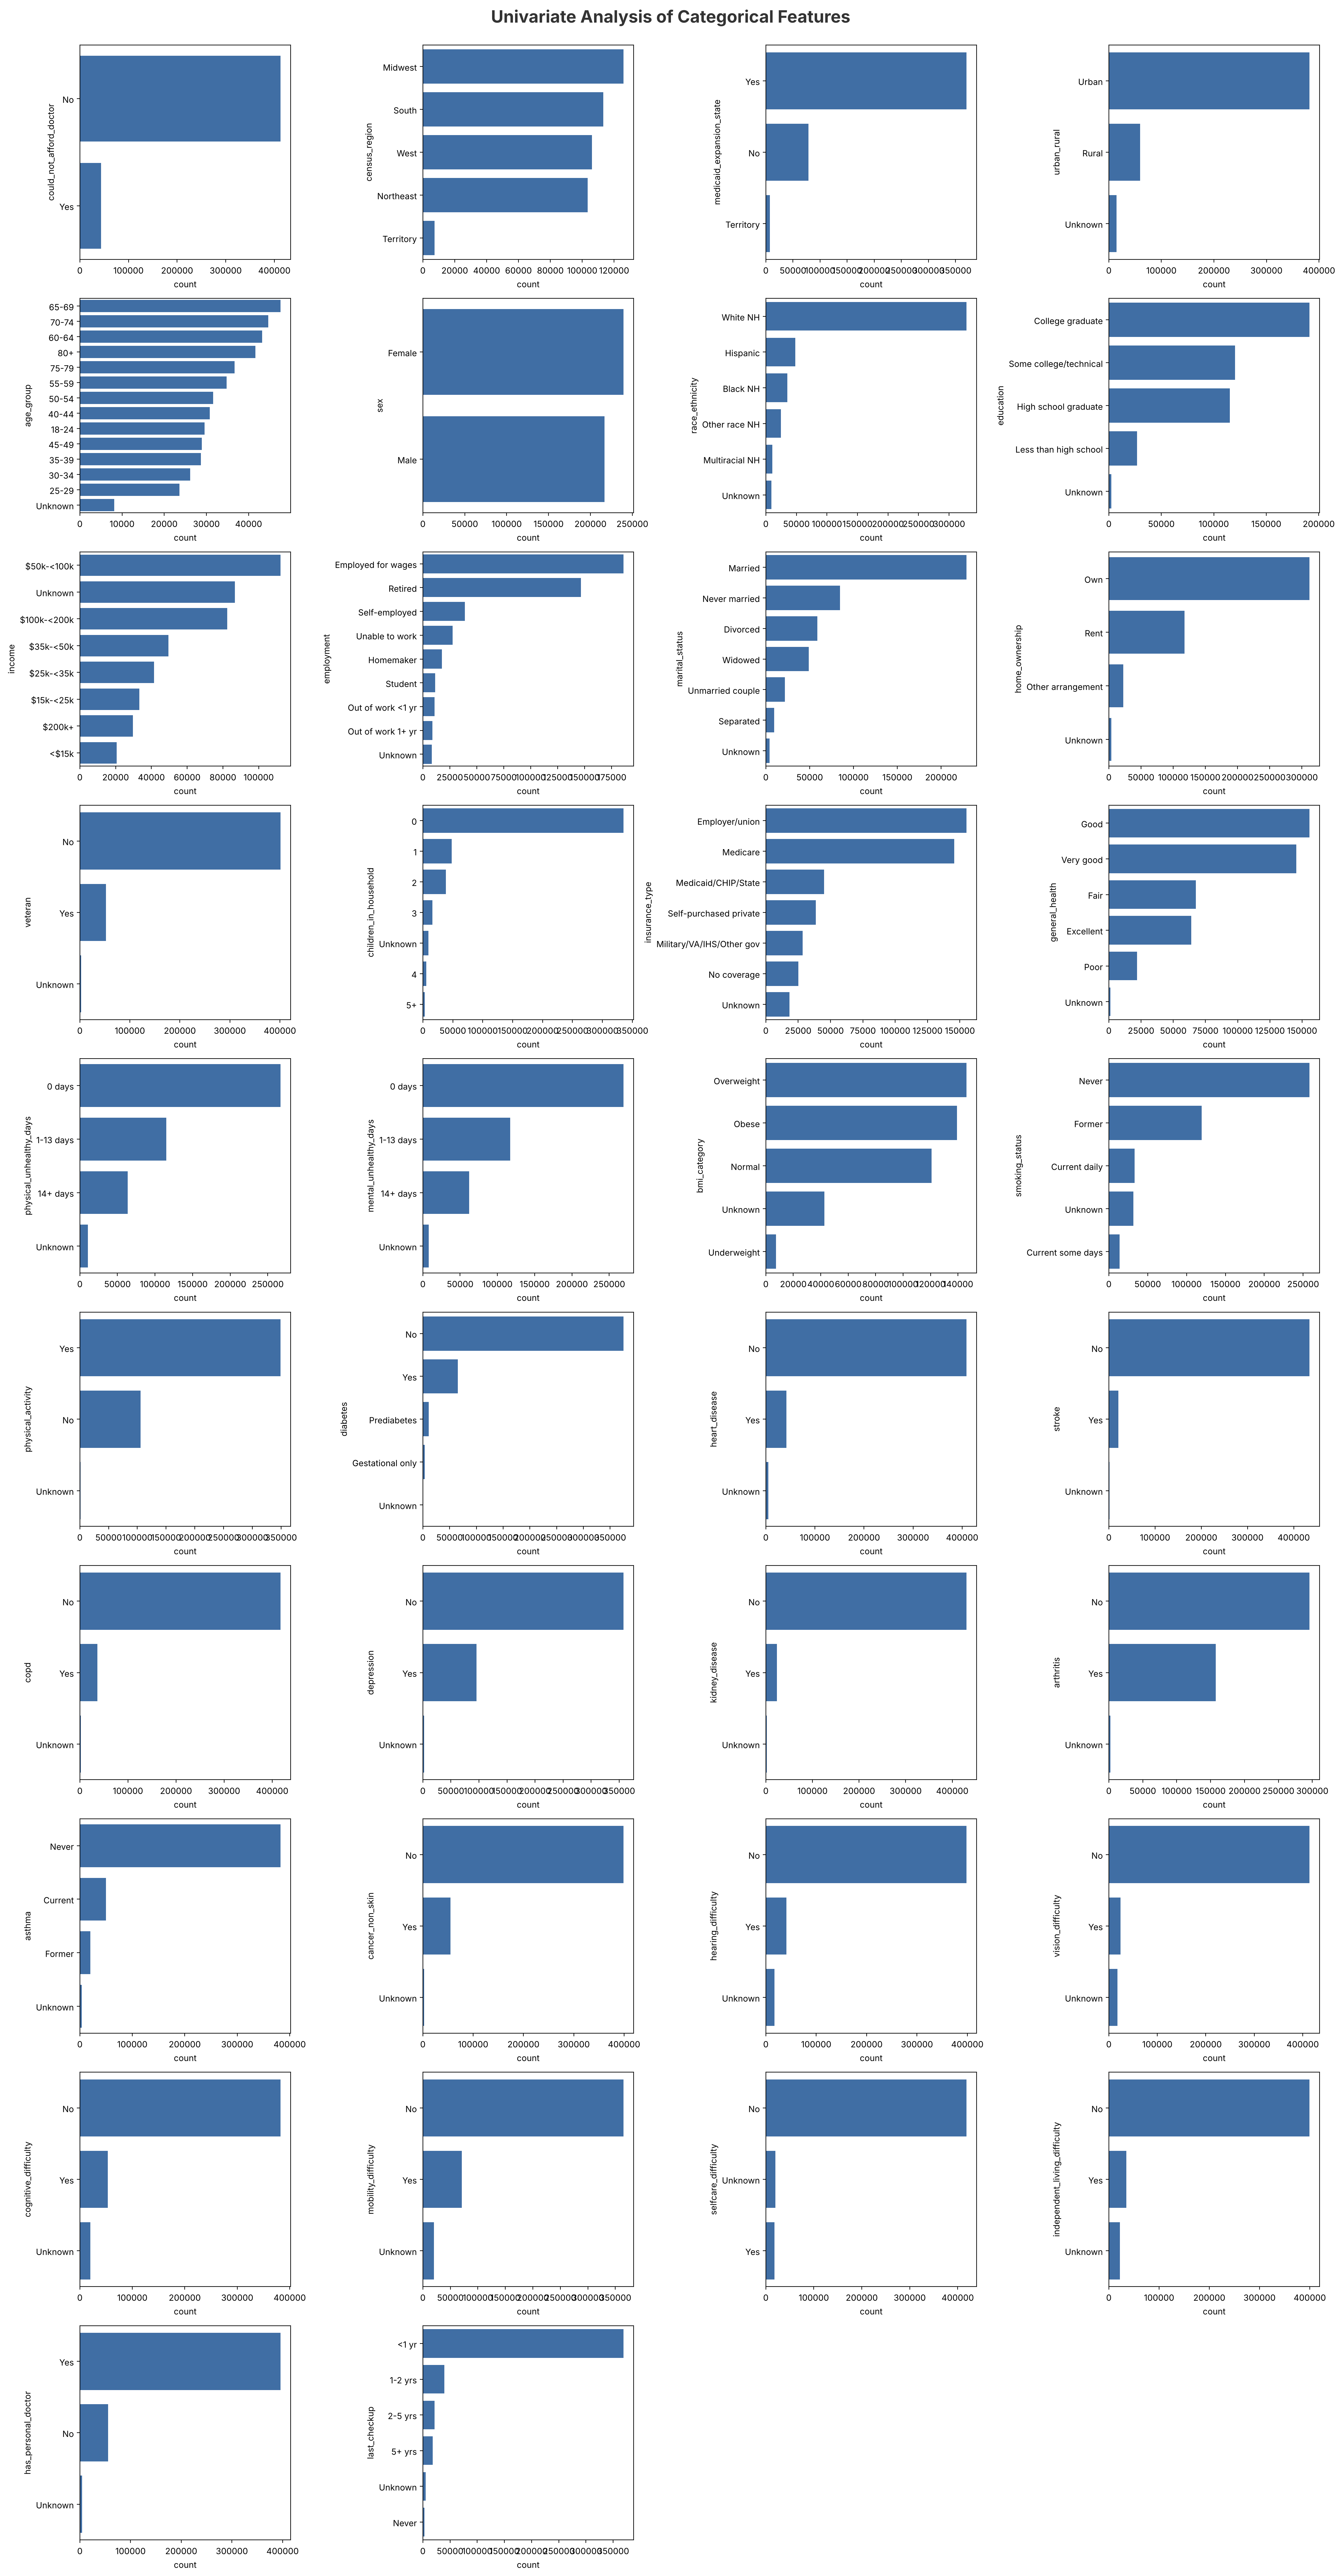

In [9]:
# categorical columns (state has 52 levels -> plotted separately in Step 11)
plot_features = [c for c in categorical_features if c != 'state']
n = len(plot_features); ncols = 4; nrows = int(np.ceil(n / ncols))
plt.figure(figsize=(22, 4.2 * nrows))
plt.suptitle('Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, n):
    plt.subplot(nrows, ncols, i+1)
    order = df[plot_features[i]].value_counts().index
    sns.countplot(y=df[plot_features[i]], order=order, color='#2f6db5')
    plt.ylabel(plot_features[i]); plt.xlabel('count')
    plt.tight_layout()

**Insights**
 - Several features are dominated by one category: `urban_rural` (mostly Urban), `veteran` (mostly No), most chronic-condition flags (mostly No), and `medicaid_expansion_state` (mostly Yes).
 - The sample is older than the U.S. adult population: **46.9%** of respondents are 60+, versus **31.7%** after weighting. That is one reason the weighted and unweighted percentages differ in Step 8.

# STEP 6 · Which features are related to the target?
> **What:** A chi-square test for every feature against `could_not_afford_doctor`, plus Cramér's V for the *strength* of each link.  
> **Why here:** We know each feature alone (Step 5), so now we link them to the target. This ranking guides the rest of the EDA and the modelling.  
> **Result of this step:** a ranking of features from strongest to weakest link

* Multivariate analysis is the analysis of more than one variable.

### Check Multicollinearity for Categorical features

* **A chi-squared test (also chi-square or χ2 test) is a statistical hypothesis test that is valid to perform when the test statistic is chi-squared distributed under the null hypothesis, specifically Pearson's chi-squared test**

* **A chi-square statistic is one way to show a relationship between two categorical variables.**

* **Here we test correlation of Categorical columns with Target column i.e could_not_afford_doctor**

Null Hypothesis ($ H_0 $): The Feature is independent of target column (No-Correlation)

Alternative Hypothesis ($ H_1 $): The Feature and Target column are not independent (Correalted)

**Important with big data:** with ~456,000 rows, even tiny, unimportant differences give p < 0.05.
So we also compute **Cramér's V** (0 = no association, 1 = perfect), which measures the *strength* of association, not just whether it exists.
Rough guide: < 0.05 negligible, 0.05–0.10 weak, 0.10–0.20 moderate, > 0.20 strong.
(The test is unweighted; it describes the sample.)

In [10]:
from scipy.stats import chi2_contingency
rows = []
for feature in [c for c in categorical_features if c != 'could_not_afford_doctor']:
    ct = pd.crosstab(df['could_not_afford_doctor'], df[feature])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append([feature, 'Reject Null Hypothesis' if p < 0.05 else 'Fail to Reject Null Hypothesis', p, cramers_v])
result = pd.DataFrame(rows, columns=['Column', 'Hypothesis Result', 'p-value', "Cramer's V"]).sort_values("Cramer's V", ascending=False)
result.reset_index(drop=True)

,Column,Hypothesis Result,p-value,Cramer's V
0,insurance_type,Reject Null Hypothesis,0.000000e+00,0.303027
1,mental_unhealthy_days,Reject Null Hypothesis,0.000000e+00,0.214453
2,age_group,Reject Null Hypothesis,0.000000e+00,0.193845
3,employment,Reject Null Hypothesis,0.000000e+00,0.191355
4,home_ownership,Reject Null Hypothesis,0.000000e+00,0.189276
5,has_personal_doctor,Reject Null Hypothesis,0.000000e+00,0.179302
6,cognitive_difficulty,Reject Null Hypothesis,0.000000e+00,0.178345
7,last_checkup,Reject Null Hypothesis,0.000000e+00,0.170884
8,general_health,Reject Null Hypothesis,0.000000e+00,0.168532
9,income,Reject Null Hypothesis,0.000000e+00,0.167498


**Report**
 - Every feature "rejects the null hypothesis". With n ≈ 456,000 that is expected and tells us little, so **use Cramér's V to rank** them.
 - **Strongest association:** `insurance_type` (V = 0.30).
 - **Moderate (V 0.10–0.22):** mental unhealthy days, age group, employment, home ownership, has personal doctor, cognitive difficulty, last checkup, general health, income, marital status, race/ethnicity, physical unhealthy days, depression, education, independent-living difficulty.
 - **Negligible (V < 0.05):** cancer, physical activity, BMI, COPD, diabetes, census region, arthritis, sex, heart disease, stroke, `medicaid_expansion_state` (0.021), kidney disease, `urban_rural` (0.015), hearing difficulty.
 - ⚠️ `has_personal_doctor` and `last_checkup` are associated with the target, but they are themselves **measures of access to care**: they can be a *consequence* of not affording a doctor. They are excluded from the main model in notebook 2, like a leakage check.

# STEP 7 · Missing and Unknown values
> **What:** Check for empty cells and measure how often each feature is "Unknown" (don't know / refused).  
> **Why here:** Data quality must be known before we trust any chart or model.  
> **Result of this step:** % Unknown per feature (income is highest at 19%)

In [11]:
df.isnull().sum().sum()

np.int64(0)

There are no NaNs, because notebook 0 coded "Don't know / Refused / not asked" as `Unknown`. The real missingness is the share of **Unknown** answers:

In [12]:
unknown_share = (df[categorical_features] == 'Unknown').mean().sort_values(ascending=False) * 100
unknown_share[unknown_share > 0].round(2).to_frame('% Unknown')

,% Unknown
income,19.01
bmi_category,9.35
smoking_status,6.96
independent_living_difficulty,4.79
cognitive_difficulty,4.44
mobility_difficulty,4.44
selfcare_difficulty,4.40
insurance_type,3.99
vision_difficulty,3.90
hearing_difficulty,3.71


**Report**
 - Unknown shares are small (< 5%) except **income (19.0%)**, **BMI (9.4%)** and **smoking (7.0%)**.
 - Keeping `Unknown` as a category is a standard, transparent approach. A sensitivity analysis (complete cases only) can be added for the paper.

# STEP 8 · The target: how common is the problem?
> **What:** Pie charts of Yes/No, both in the sample and for all U.S. adults (survey-weighted).  
> **Why here:** Everything from here on is about *who* says Yes, so we first measure how many do.  
> **Result of this step:** **9.5% Yes** (sample) · **12.3% Yes** (U.S. adults)

### 8a · Visualize the Target Feature

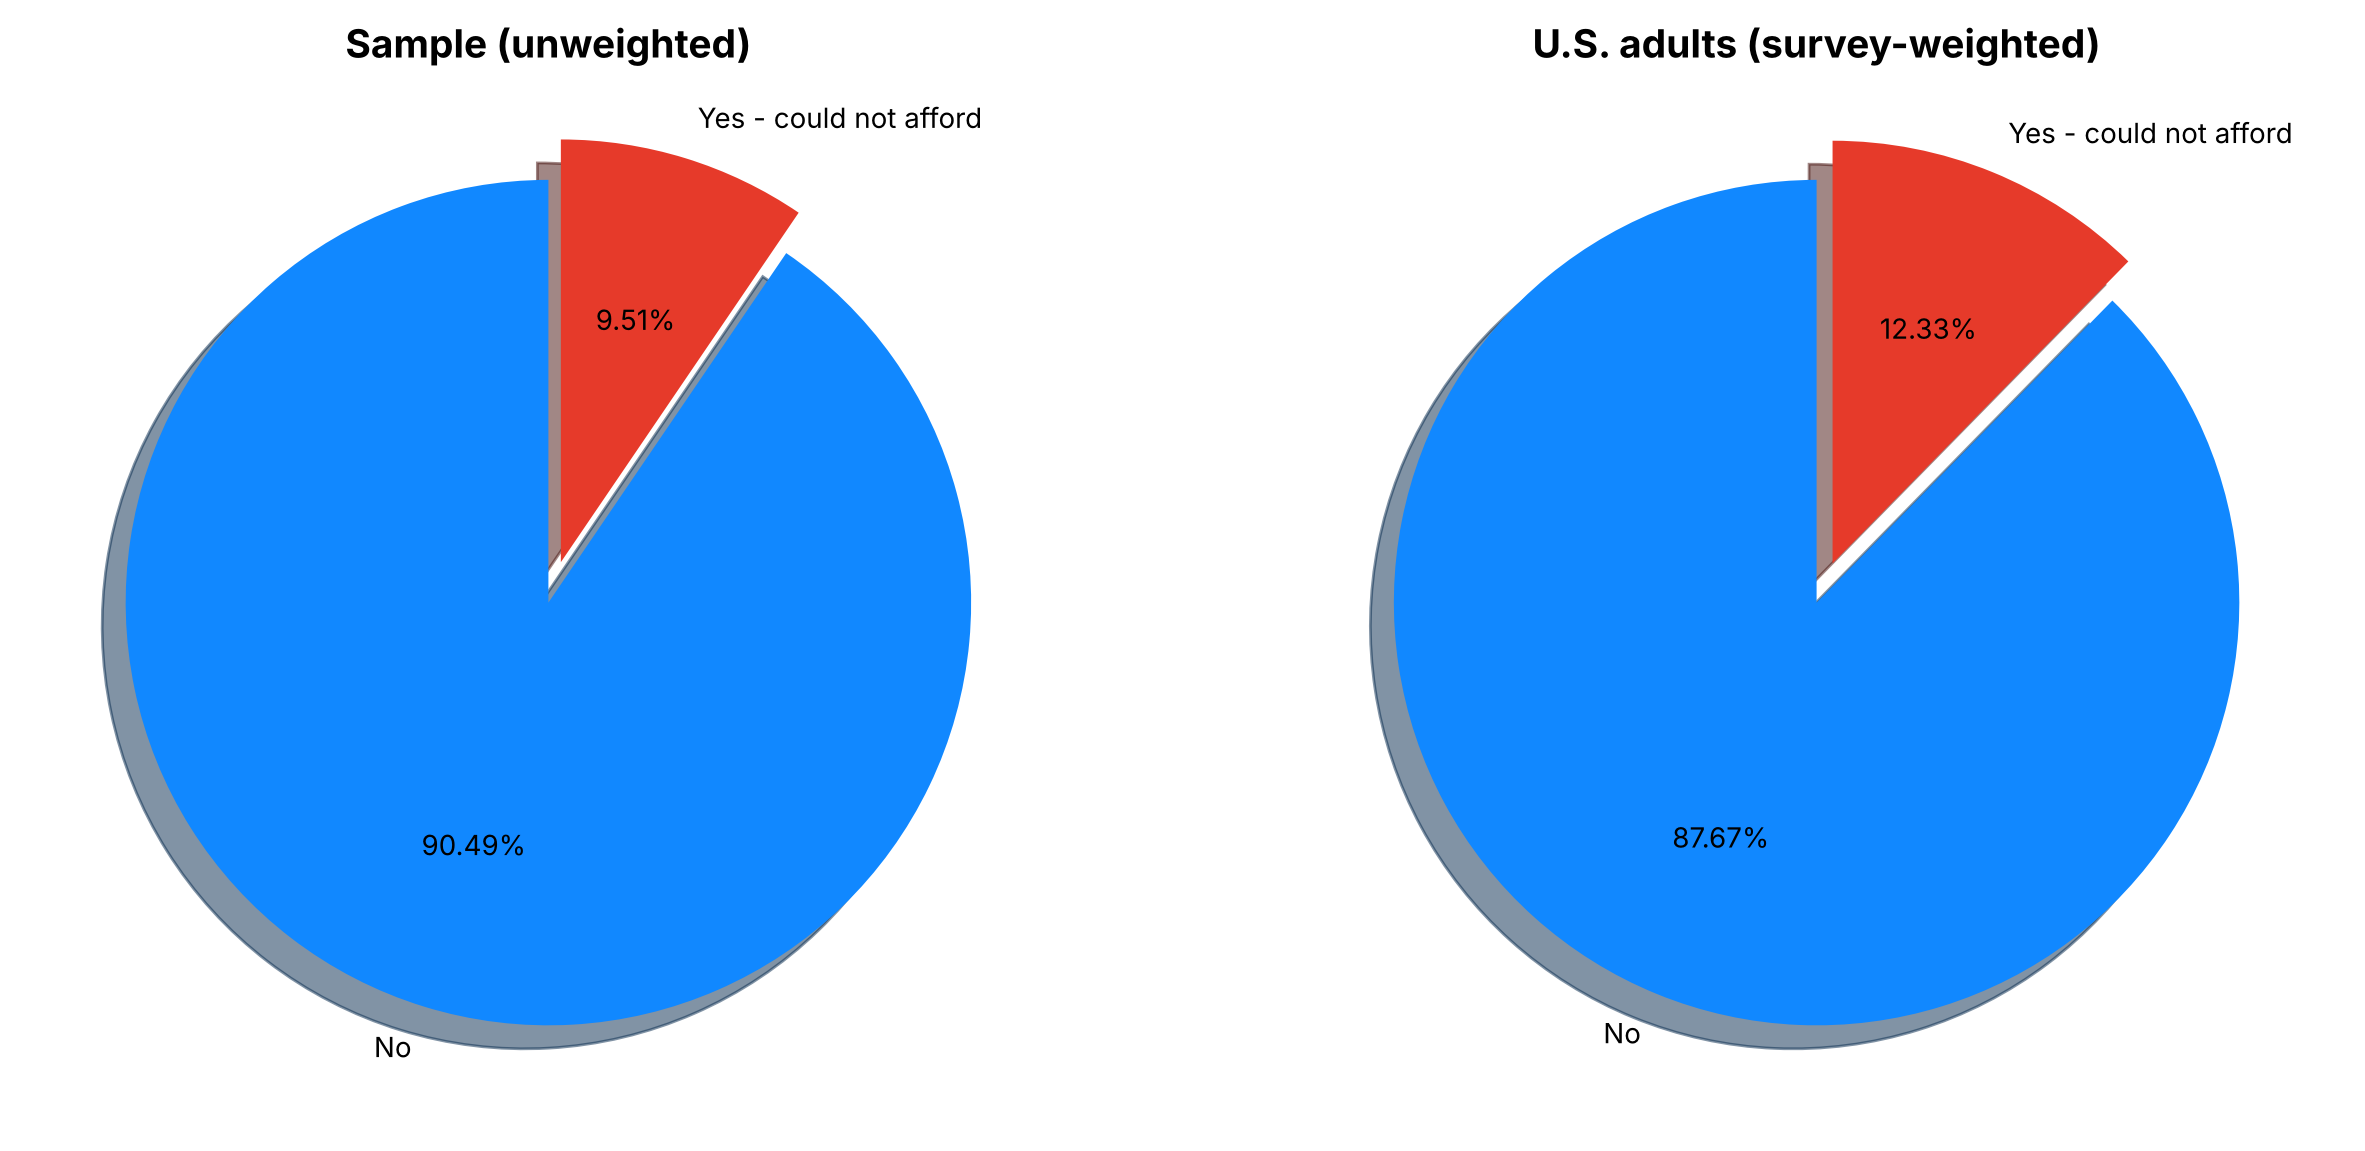

Unweighted %: {'No': 90.49, 'Yes': 9.51}
Weighted %: {'No': 87.67, 'Yes': 12.33}


In [13]:
w = df['survey_weight']
unweighted = df.could_not_afford_doctor.value_counts(normalize=True) * 100
weighted = df.groupby('could_not_afford_doctor')['survey_weight'].sum() / w.sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
colors = {'No': '#1188ff', 'Yes': '#e63a2a'}
for a, s, t in [(ax[0], unweighted, 'Sample (unweighted)'), (ax[1], weighted, 'U.S. adults (survey-weighted)')]:
    s = s.reindex(['No', 'Yes'])
    a.pie(s, labels=['No', 'Yes - could not afford'], startangle=90, autopct='%1.2f%%',
          explode=(0, 0.1), shadow=True, colors=[colors[k] for k in s.index])
    a.set_title(t, fontsize=14, fontweight='bold')
plt.show()
print('Unweighted %:', unweighted.round(2).to_dict()); print('Weighted %:', weighted.round(2).to_dict())

* The target is **imbalanced**: 9.51% Yes in the sample vs **12.33% Yes among U.S. adults (weighted)**.
* The weighted rate is higher because groups with more cost barriers (younger adults, Hispanic adults, people without coverage) are under-represented in the raw sample, and the weights correct for this.
* This is why a model evaluated only on accuracy would look great by predicting "No" for everyone (90.5%).

# STEP 9 · A reusable plotting tool
> **What:** Define `plot_factor()`, which draws the two charts used for every factor in Step 10.  
> **Why here:** We need the same two charts 13 times, so we write the code once.  
> **Result of this step:** a helper function (no output yet)

**Helper used in Step 10.** For each factor it shows:
(1) a count plot by target, like the visa notebook, and
(2) the **% who could not afford a doctor** in each group, both unweighted and survey-weighted.
The weighted bar is the population estimate we'd report in a paper.

In [14]:
def target_rate_table(col, order=None):
    g = df.groupby(col)
    out = pd.DataFrame({
        'n': g.size(),
        '% Yes (sample)': g['could_not_afford_doctor'].apply(lambda s: (s == 'Yes').mean() * 100),
        '% Yes (weighted)': g.apply(lambda d: d.loc[d.could_not_afford_doctor == 'Yes', 'survey_weight'].sum()
                                    / d['survey_weight'].sum() * 100),
    })
    if order is not None:
        out = out.reindex([o for o in order if o in out.index])
    return out.round(2)

def plot_factor(col, order=None, title=None, rotate=0):
    tab = target_rate_table(col, order)
    order = list(tab.index)
    fig, ax = plt.subplots(1, 2, figsize=(18, 6))
    sns.countplot(x=col, hue='could_not_afford_doctor', data=df, order=order, ec='black',
                  palette={'No': '#1188ff', 'Yes': '#e63a2a'}, ax=ax[0])
    ax[0].set_title(f'{title or col} vs Could not afford doctor', weight='bold', fontsize=14)
    ax[0].tick_params(axis='x', rotation=rotate); ax[0].set_ylabel('Count')
    x = np.arange(len(order))
    ax[1].bar(x - 0.2, tab['% Yes (sample)'], 0.4, label='sample', color='#9fb7d9', ec='black')
    ax[1].bar(x + 0.2, tab['% Yes (weighted)'], 0.4, label='weighted (U.S. adults)', color='#e63a2a', ec='black')
    for i, v in enumerate(tab['% Yes (weighted)']):
        ax[1].text(i + 0.2, v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)
    ax[1].set_xticks(x); ax[1].set_xticklabels(order, rotation=rotate)
    ax[1].set_title(f'% who could not afford a doctor, by {title or col}', weight='bold', fontsize=14)
    ax[1].set_ylabel('%'); ax[1].legend()
    plt.tight_layout(); plt.show()
    return tab

# STEP 10 · Factor by factor: does it change the risk?
> **What:** For 13 factors: a count chart plus the % who could not afford a doctor (sample and survey-weighted), followed by a short report.  
> **Why here:** Step 6 ranked the factors. Here we *see* how each one changes the risk, in the order that matters most for the question.  
> **Result of this step:** 13 chart pairs (10.1 to 10.13), each with a report

### 10.1 Does health insurance type have any impact on cost barriers?

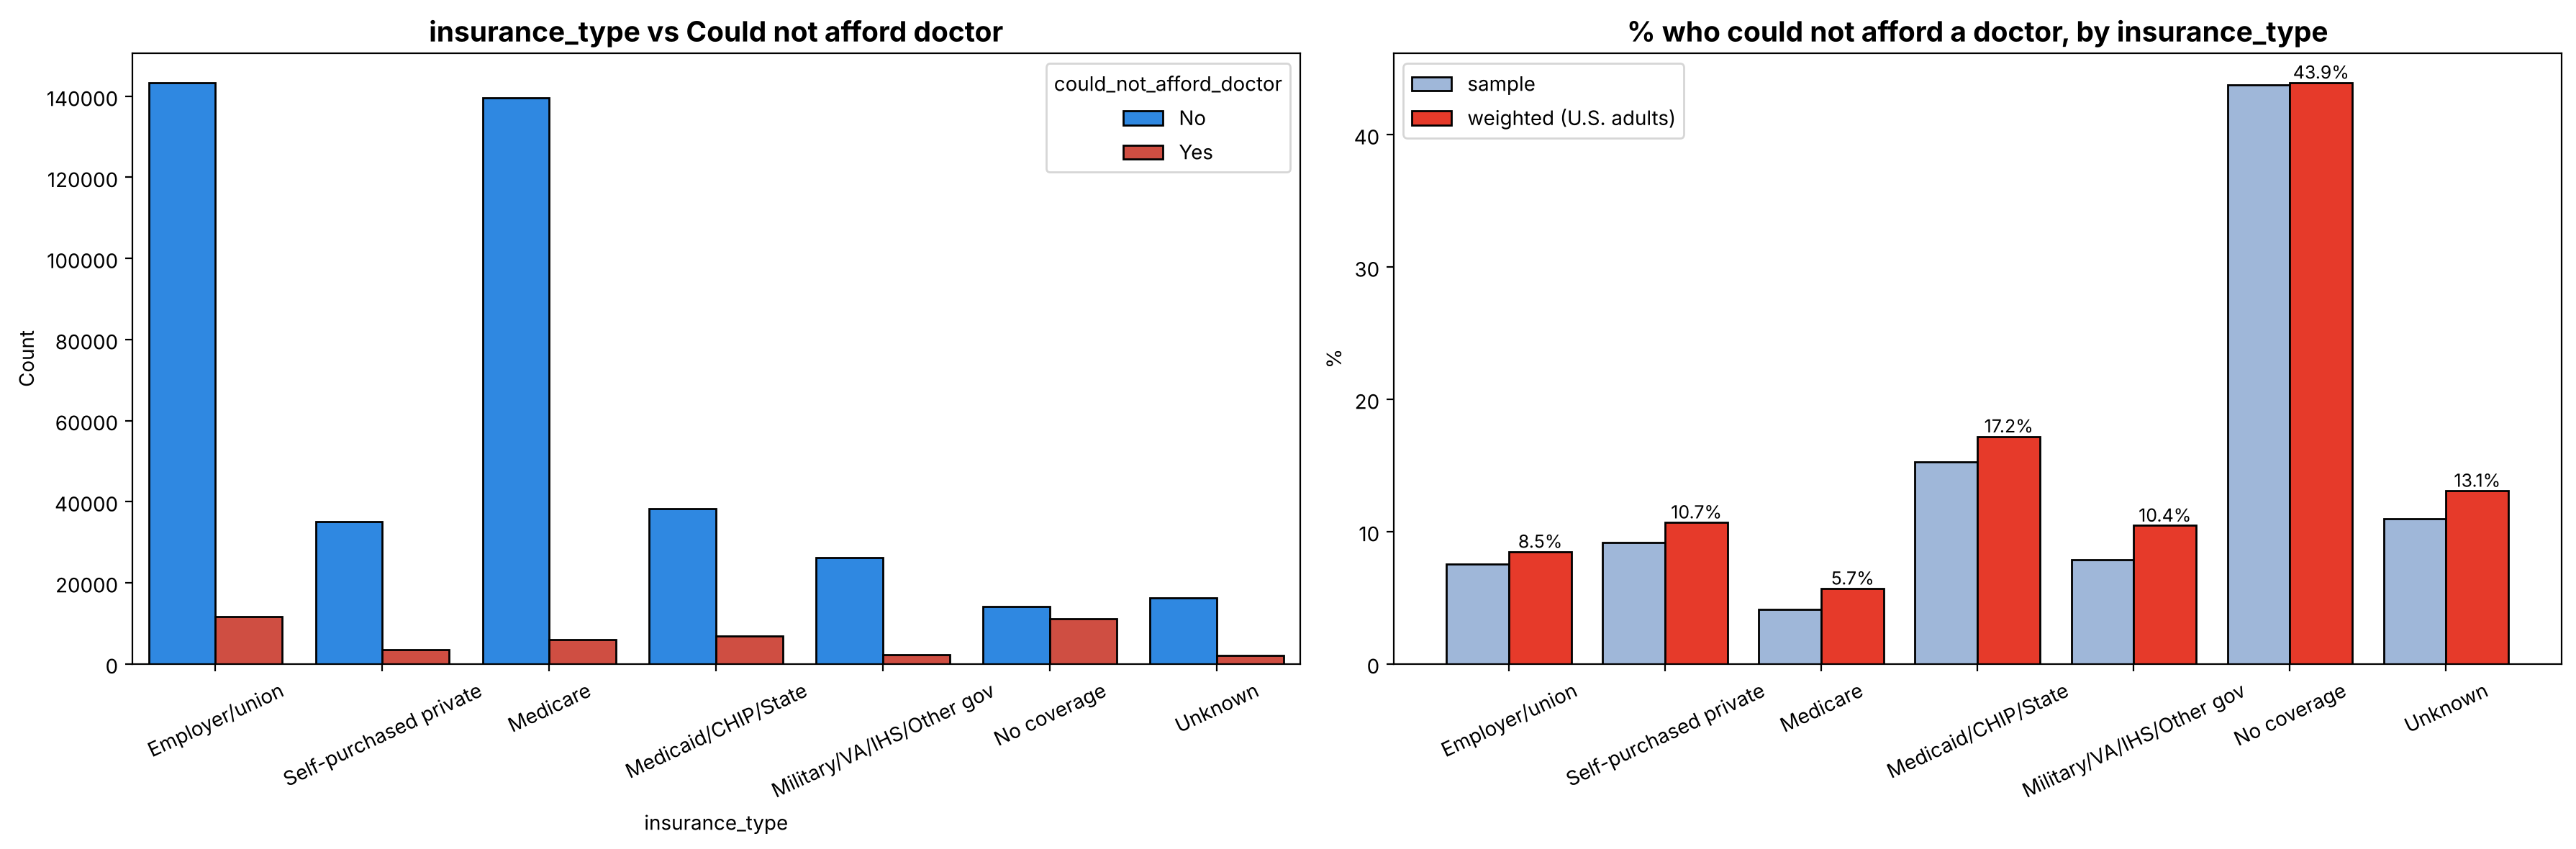

,n,% Yes (sample),% Yes (weighted)
insurance_type,,,
Employer/union,155078,7.54,8.47
Self-purchased private,38529,9.18,10.69
Medicare,145556,4.12,5.69
Medicaid/CHIP/State,45092,15.28,17.19
Military/VA/IHS/Other gov,28353,7.85,10.45
No coverage,25197,43.77,43.94
Unknown,18192,10.98,13.08


In [15]:
plot_factor('insurance_type', order=['Employer/union','Self-purchased private','Medicare','Medicaid/CHIP/State','Military/VA/IHS/Other gov','No coverage','Unknown'], rotate=25)

**Report**
* **No coverage: 43.9%** could not afford a doctor (weighted), about 5× the rate for employer/union coverage (8.5%).
* **Medicaid/CHIP/State: 17.2%**, the highest among insured groups.
* **Medicare: 5.7%**, the lowest. This reflects both coverage and the older age of this group.
* Insurance is the single strongest factor (Cramér's V = 0.30).

### 10.2 Does household income have any impact?

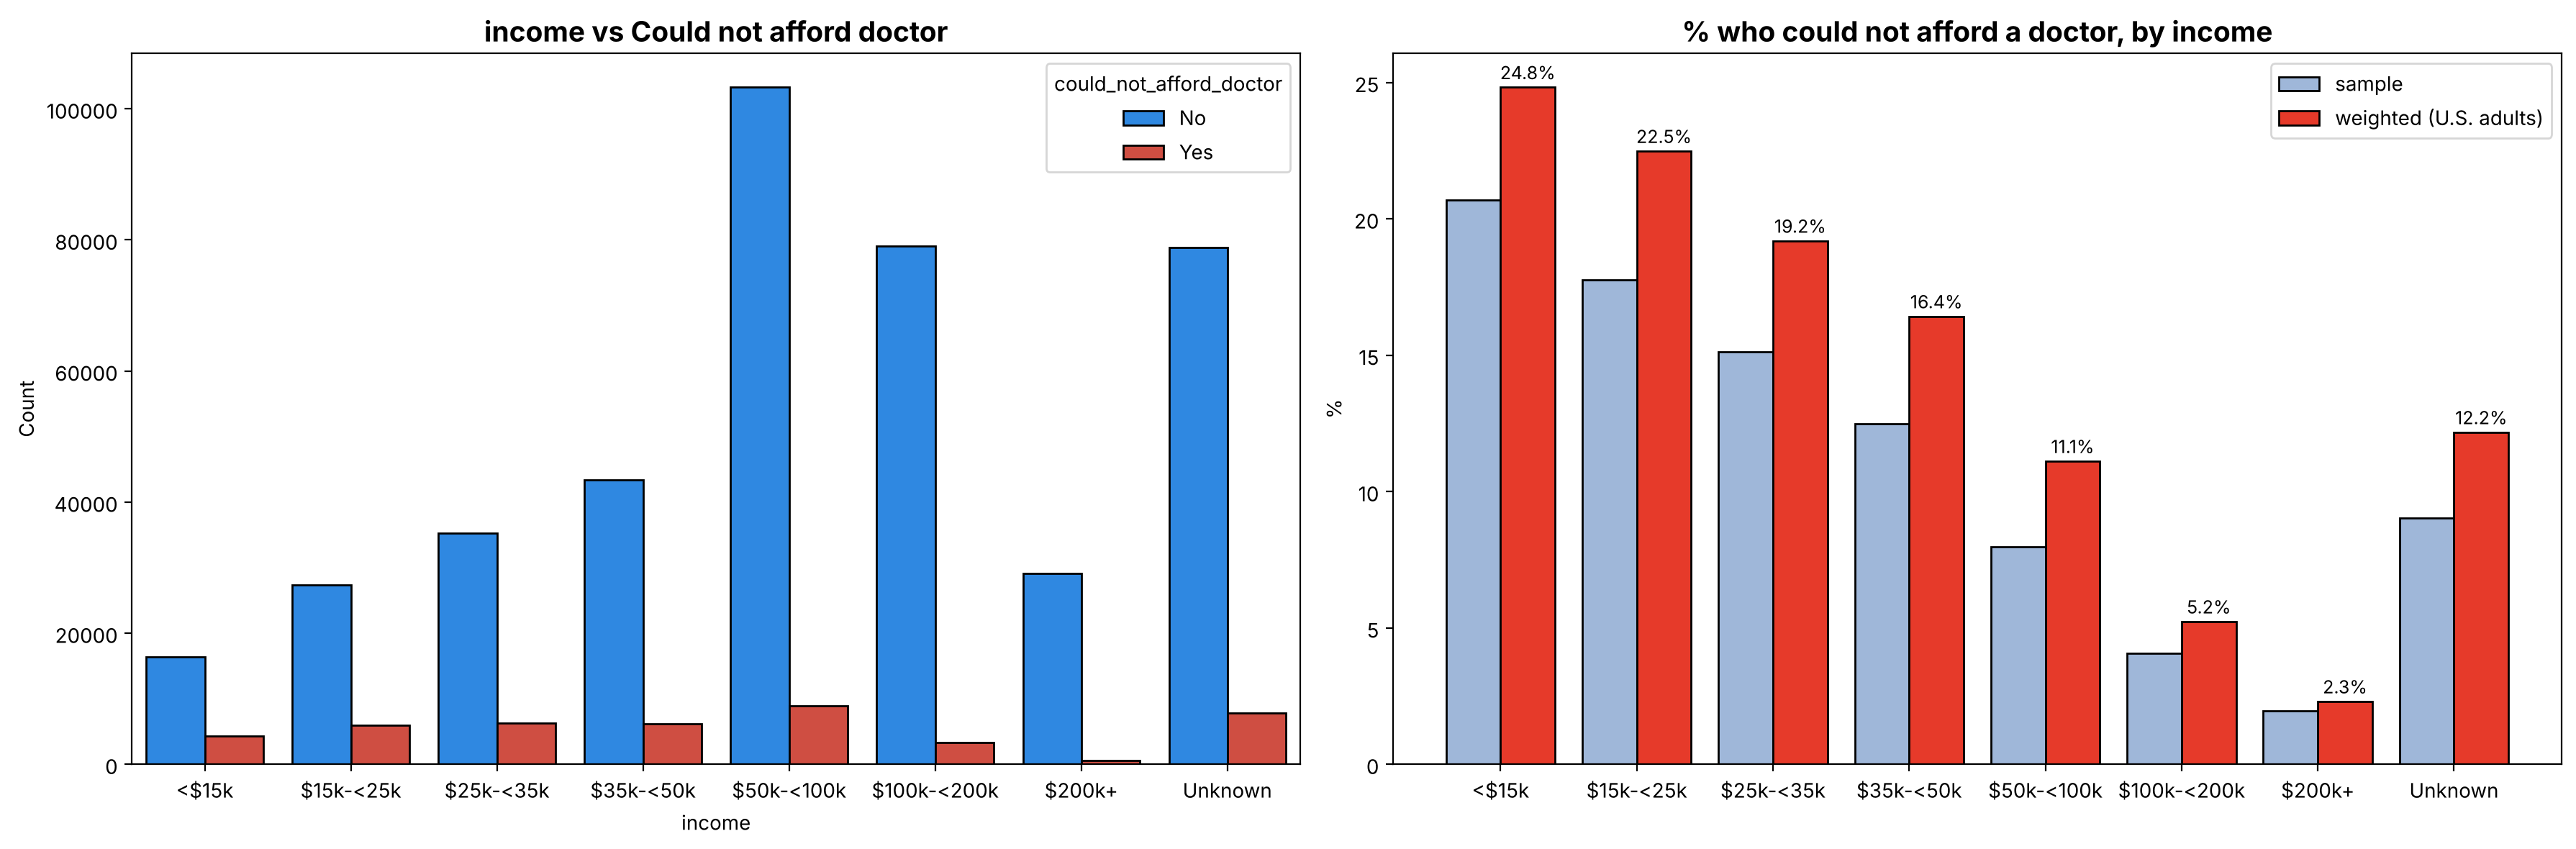

,n,% Yes (sample),% Yes (weighted)
income,,,
<$15k,20646,20.69,24.82
$15k-<25k,33302,17.77,22.48
$25k-<35k,41540,15.12,19.19
$35k-<50k,49566,12.48,16.42
$50k-<100k,112205,7.96,11.11
$100k-<200k,82369,4.07,5.23
$200k+,29678,1.97,2.30
Unknown,86691,9.04,12.17


In [16]:
plot_factor('income', order=['<$15k','$15k-<25k','$25k-<35k','$35k-<50k','$50k-<100k','$100k-<200k','$200k+','Unknown'], rotate=0)

**Report**
* A clear **gradient**: from **24.8%** (<$15k) down to **2.3%** ($200k+), weighted. Each step up in income lowers the rate.
* The `Unknown` income group (12.2%) sits close to the overall average (12.3%).

### 10.3 Does age have any impact?

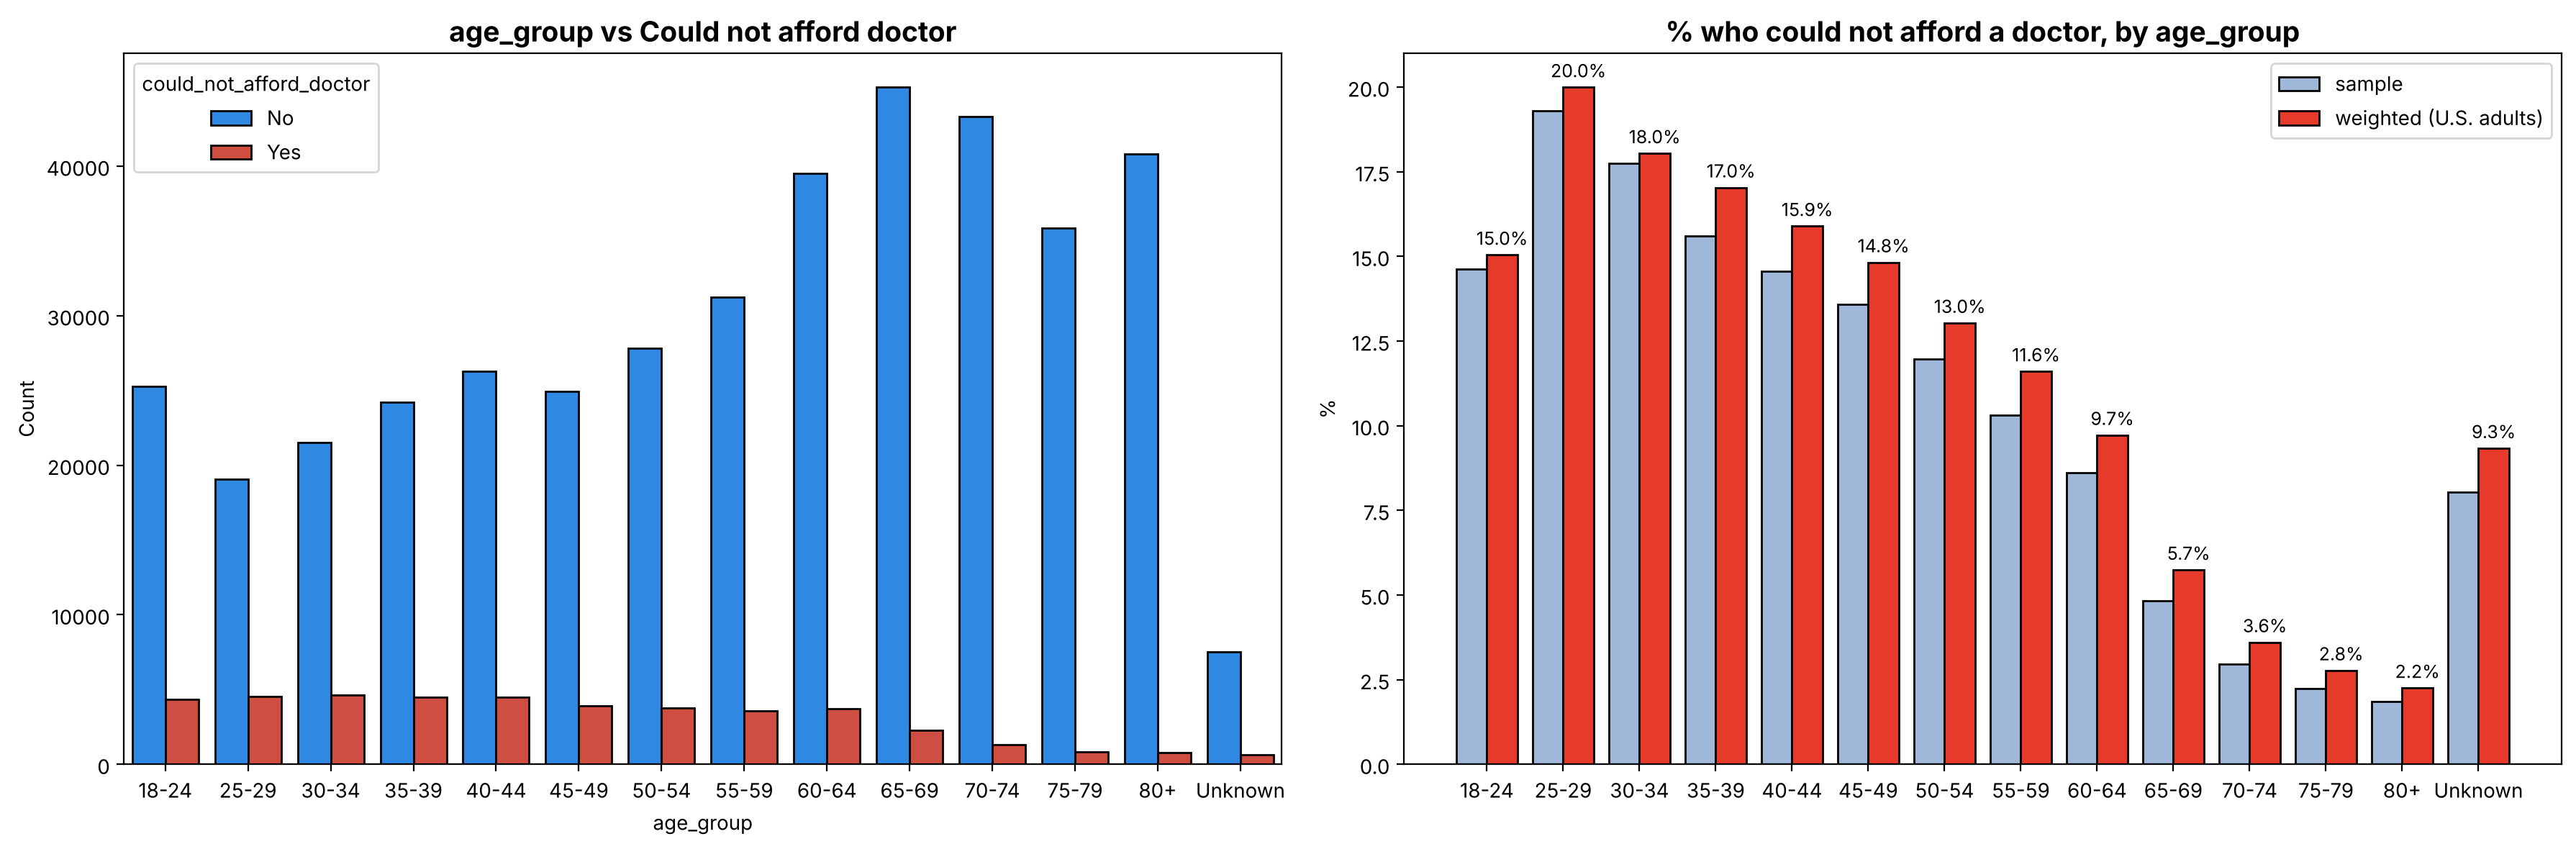

,n,% Yes (sample),% Yes (weighted)
age_group,,,
18-24,29585,14.62,15.04
25-29,23601,19.30,19.99
30-34,26139,17.74,18.04
35-39,28704,15.60,17.03
40-44,30783,14.56,15.89
45-49,28876,13.59,14.82
50-54,31589,11.97,13.03
55-59,34820,10.31,11.60
60-64,43241,8.61,9.72


In [17]:
plot_factor('age_group', order=['18-24','25-29','30-34','35-39','40-44','45-49','50-54','55-59','60-64','65-69','70-74','75-79','80+','Unknown'], rotate=0)

**Report**
* The rate peaks at **25–29 (20.0%)** and stays above 15% until the mid-40s.
* It drops sharply at **65+** (5.7% at 65–69, 2.3% at 80+). That age is when Medicare eligibility begins, so age and insurance are strongly linked.

### 10.4 Does race/ethnicity have any impact?

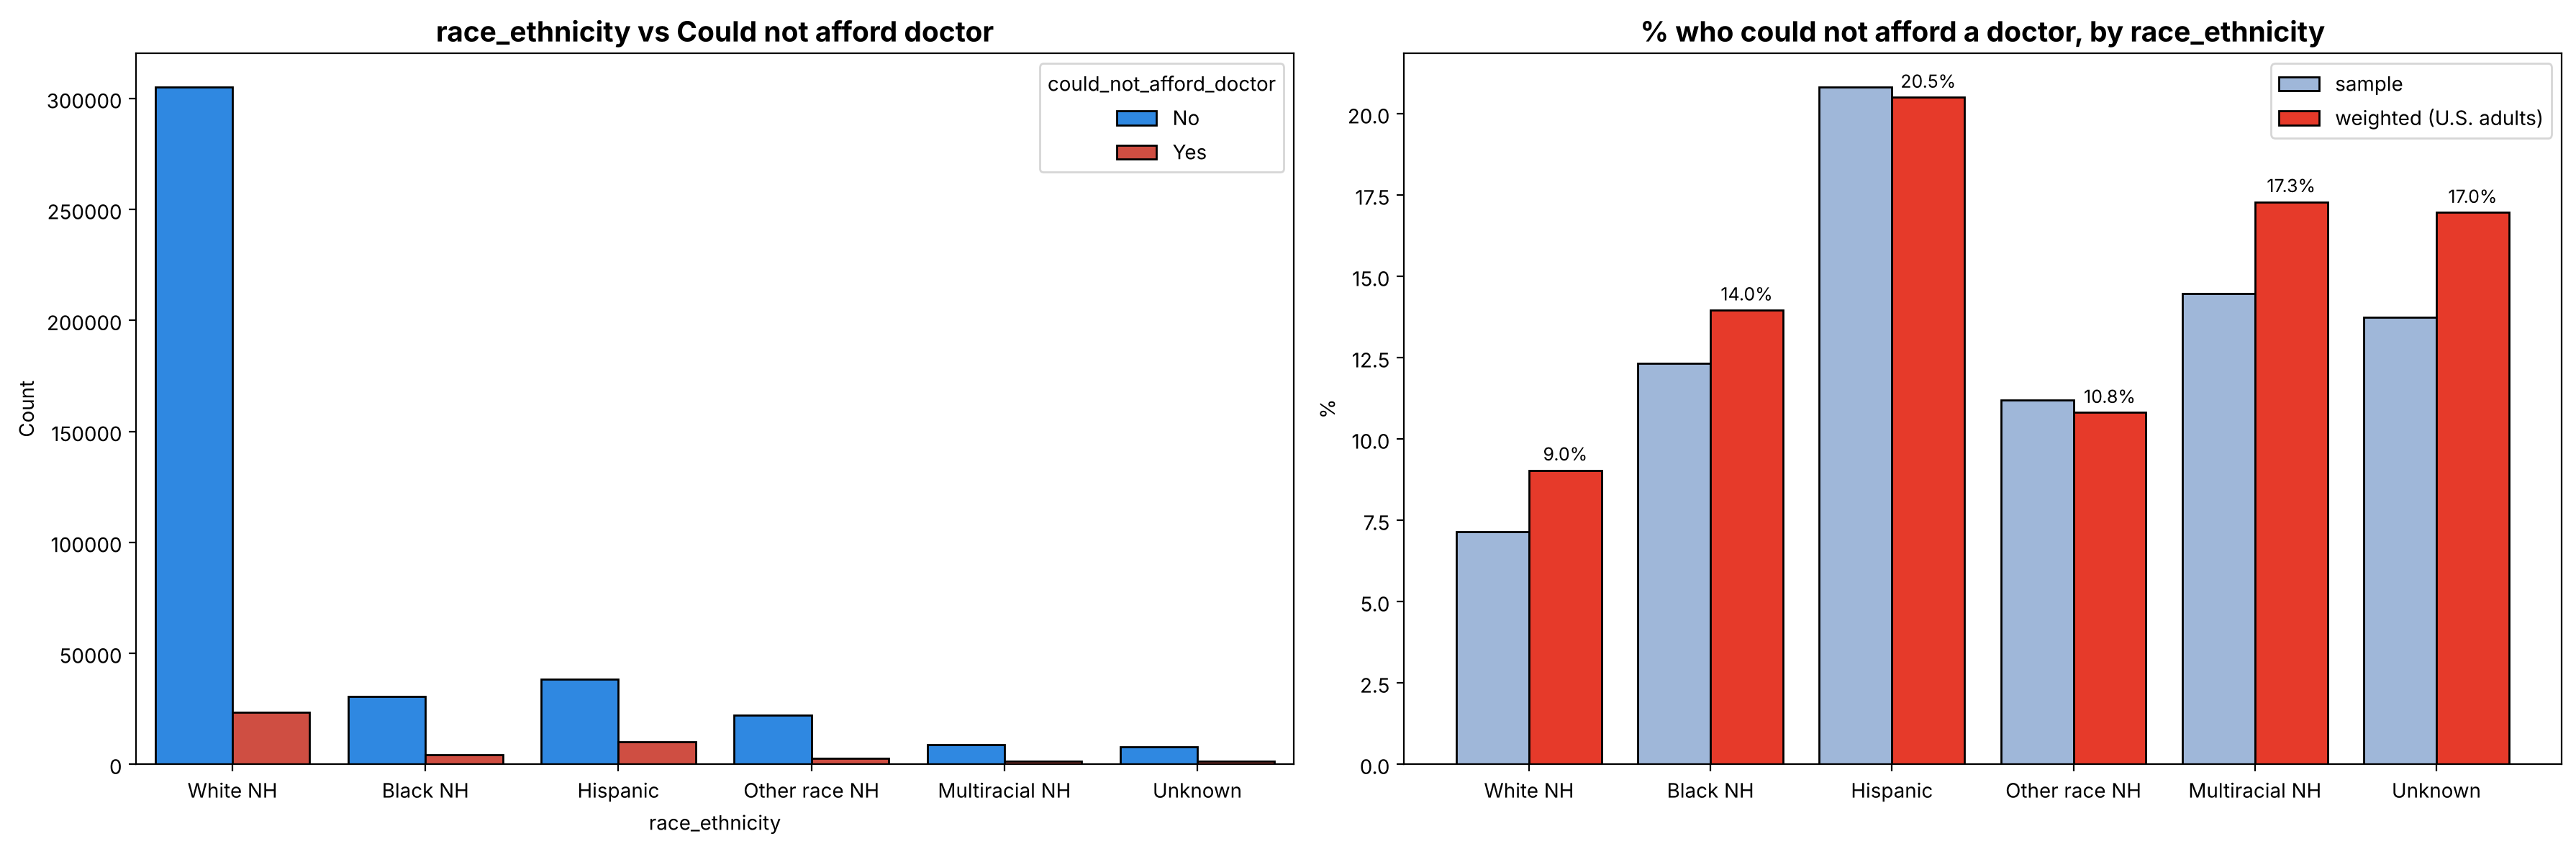

,n,% Yes (sample),% Yes (weighted)
race_ethnicity,,,
White NH,328488,7.15,9.04
Black NH,34999,12.33,13.96
Hispanic,48414,20.81,20.50
Other race NH,24747,11.19,10.81
Multiracial NH,10425,14.47,17.29
Unknown,8924,13.74,16.96


In [18]:
plot_factor('race_ethnicity', order=['White NH','Black NH','Hispanic','Other race NH','Multiracial NH','Unknown'], rotate=0)

**Report**
* **Hispanic adults: 20.5%** and **Multiracial NH: 17.3%** are the highest, weighted.
* Black NH 14.0%, Other race NH 10.8%, **White NH 9.0%** (lowest).
* These gaps are why notebook 2 checks whether the model performs **equally well across race/ethnicity groups**.

### 10.5 Does education have any impact?

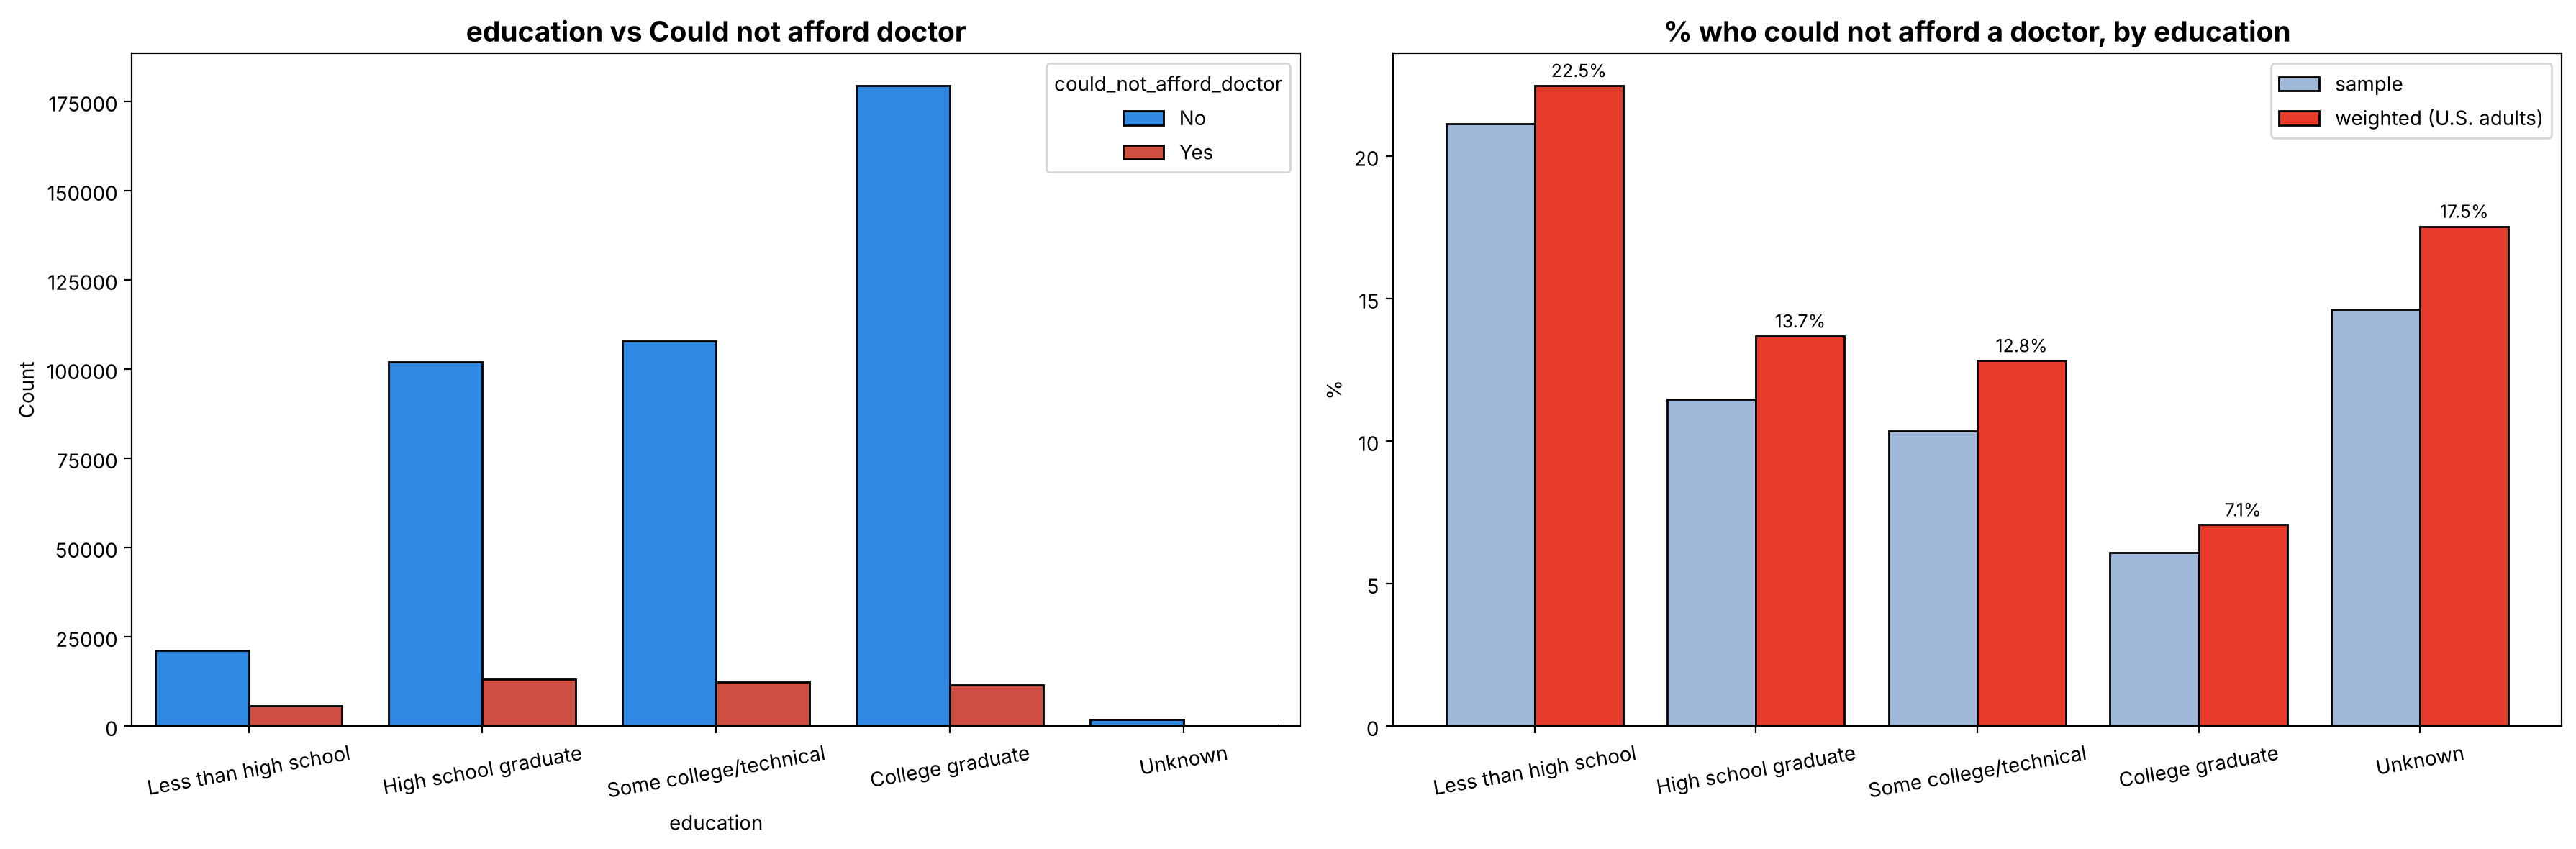

,n,% Yes (sample),% Yes (weighted)
education,,,
Less than high school,26933,21.14,22.48
High school graduate,115313,11.46,13.69
Some college/technical,120340,10.36,12.83
College graduate,191155,6.10,7.07
Unknown,2256,14.63,17.54


In [19]:
plot_factor('education', order=['Less than high school','High school graduate','Some college/technical','College graduate','Unknown'], rotate=10)

**Report**
* **Less than high school: 22.5%** vs **college graduate: 7.1%** (weighted), a 3× difference.

### 10.6 Does employment status have any impact?

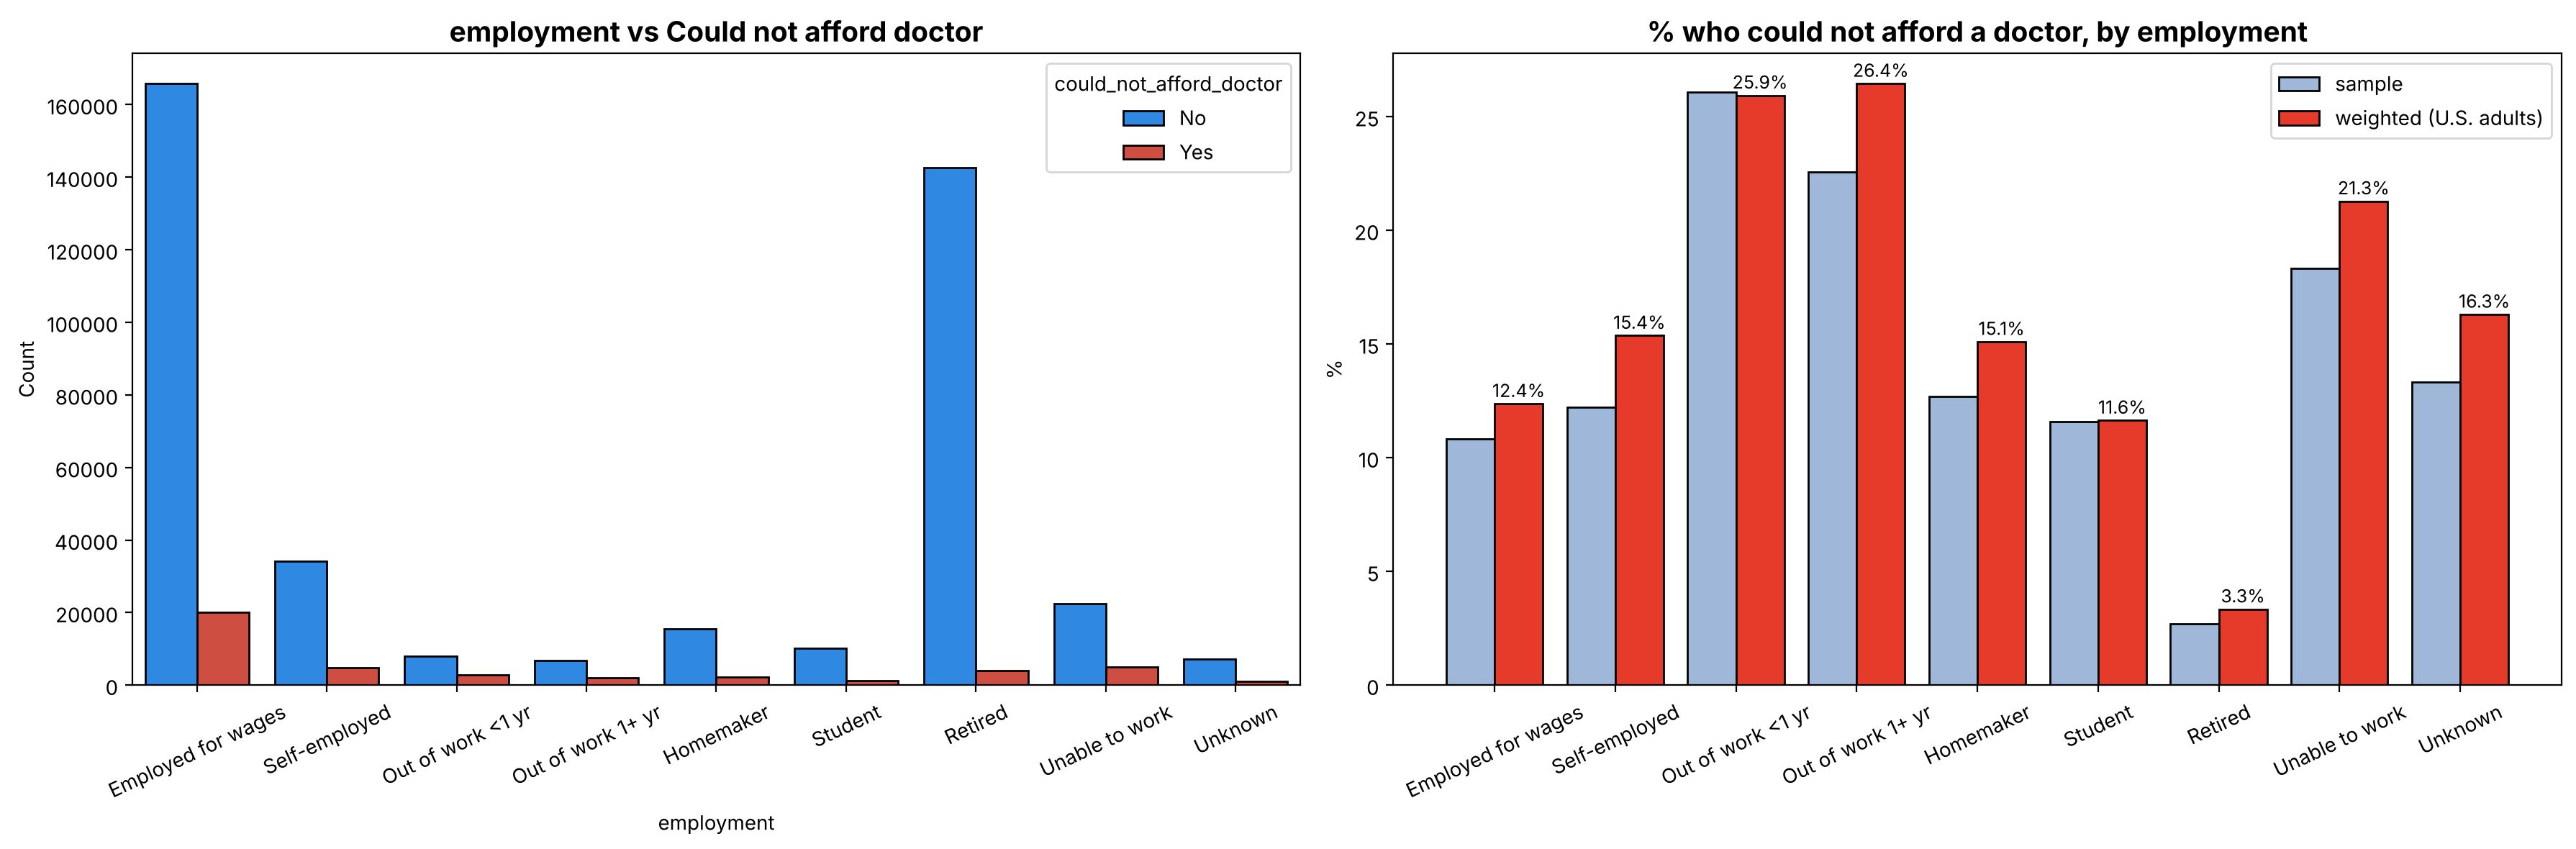

,n,% Yes (sample),% Yes (weighted)
employment,,,
Employed for wages,185931,10.83,12.37
Self-employed,38991,12.23,15.37
Out of work <1 yr,10758,26.06,25.93
Out of work 1+ yr,8893,22.56,26.45
Homemaker,17765,12.68,15.10
Student,11424,11.60,11.64
Retired,146504,2.69,3.34
Unable to work,27516,18.31,21.28
Unknown,8215,13.33,16.30


In [20]:
plot_factor('employment', order=['Employed for wages','Self-employed','Out of work <1 yr','Out of work 1+ yr','Homemaker','Student','Retired','Unable to work','Unknown'], rotate=25)

**Report**
* **Out of work** (≈26% for both <1 yr and 1+ yr) and **unable to work (21.3%)** are the highest.
* **Self-employed (15.4%)** is higher than employed for wages (12.4%), consistent with less access to employer coverage.
* **Retired: 3.3%**, the lowest (mostly Medicare age).

### 10.7 Does living in a Medicaid-expansion state have any impact?

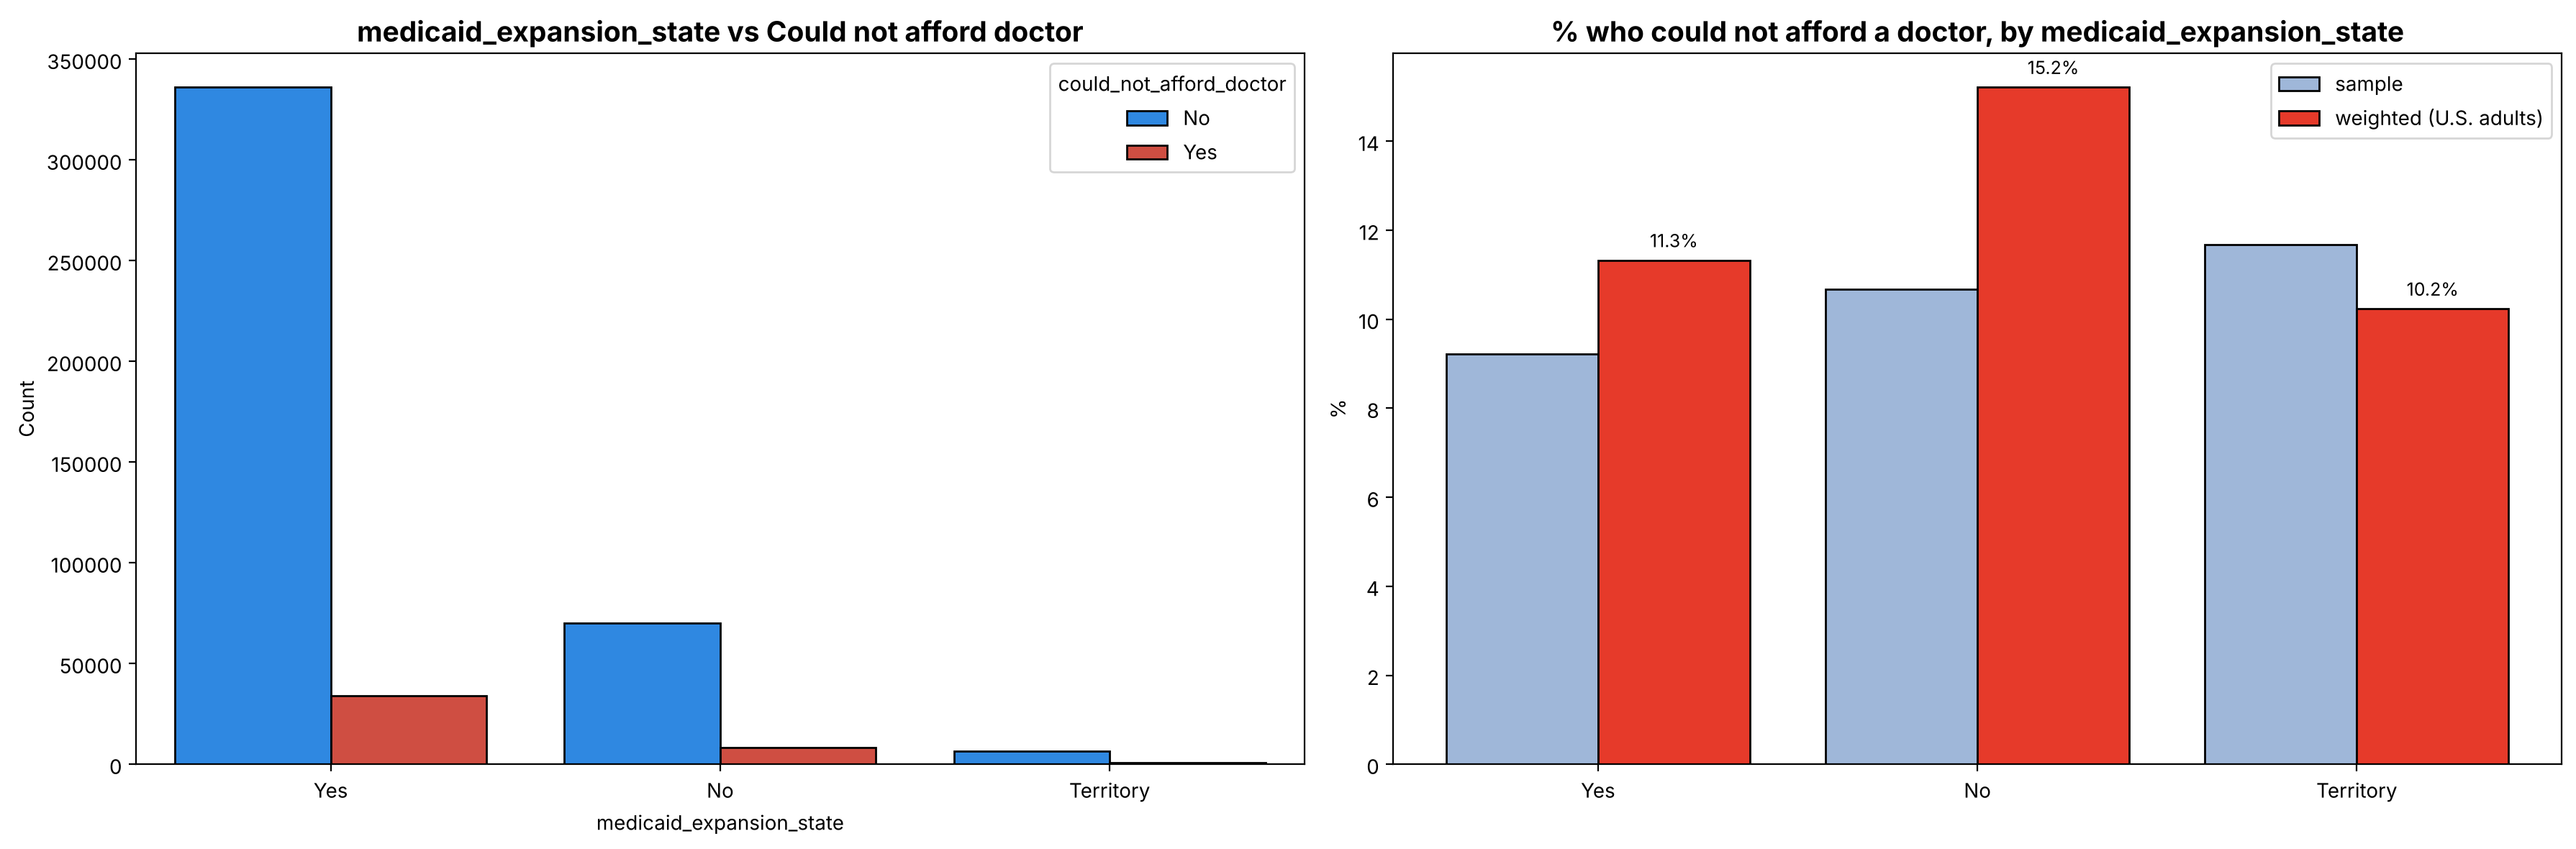

,n,% Yes (sample),% Yes (weighted)
medicaid_expansion_state,,,
Yes,370198,9.22,11.32
No,78497,10.68,15.21
Territory,7302,11.67,10.23


In [21]:
plot_factor('medicaid_expansion_state', order=['Yes','No','Territory'], rotate=0)

**Report**
* Weighted: **15.2%** in non-expansion states vs **11.3%** in expansion states, a 3.9-point gap in U.S. adults.
* In the *unweighted* sample the gap is smaller (10.7% vs 9.2%), and Cramér's V is tiny (0.021). Non-expansion states include large states (Texas, Florida, Georgia) that the weights scale up.
* This is a **state-level policy** variable. It describes *where* people live, not individual eligibility, so the paper must interpret it as an association, not a causal effect.

### 10.8 Does urban vs rural residence have any impact?

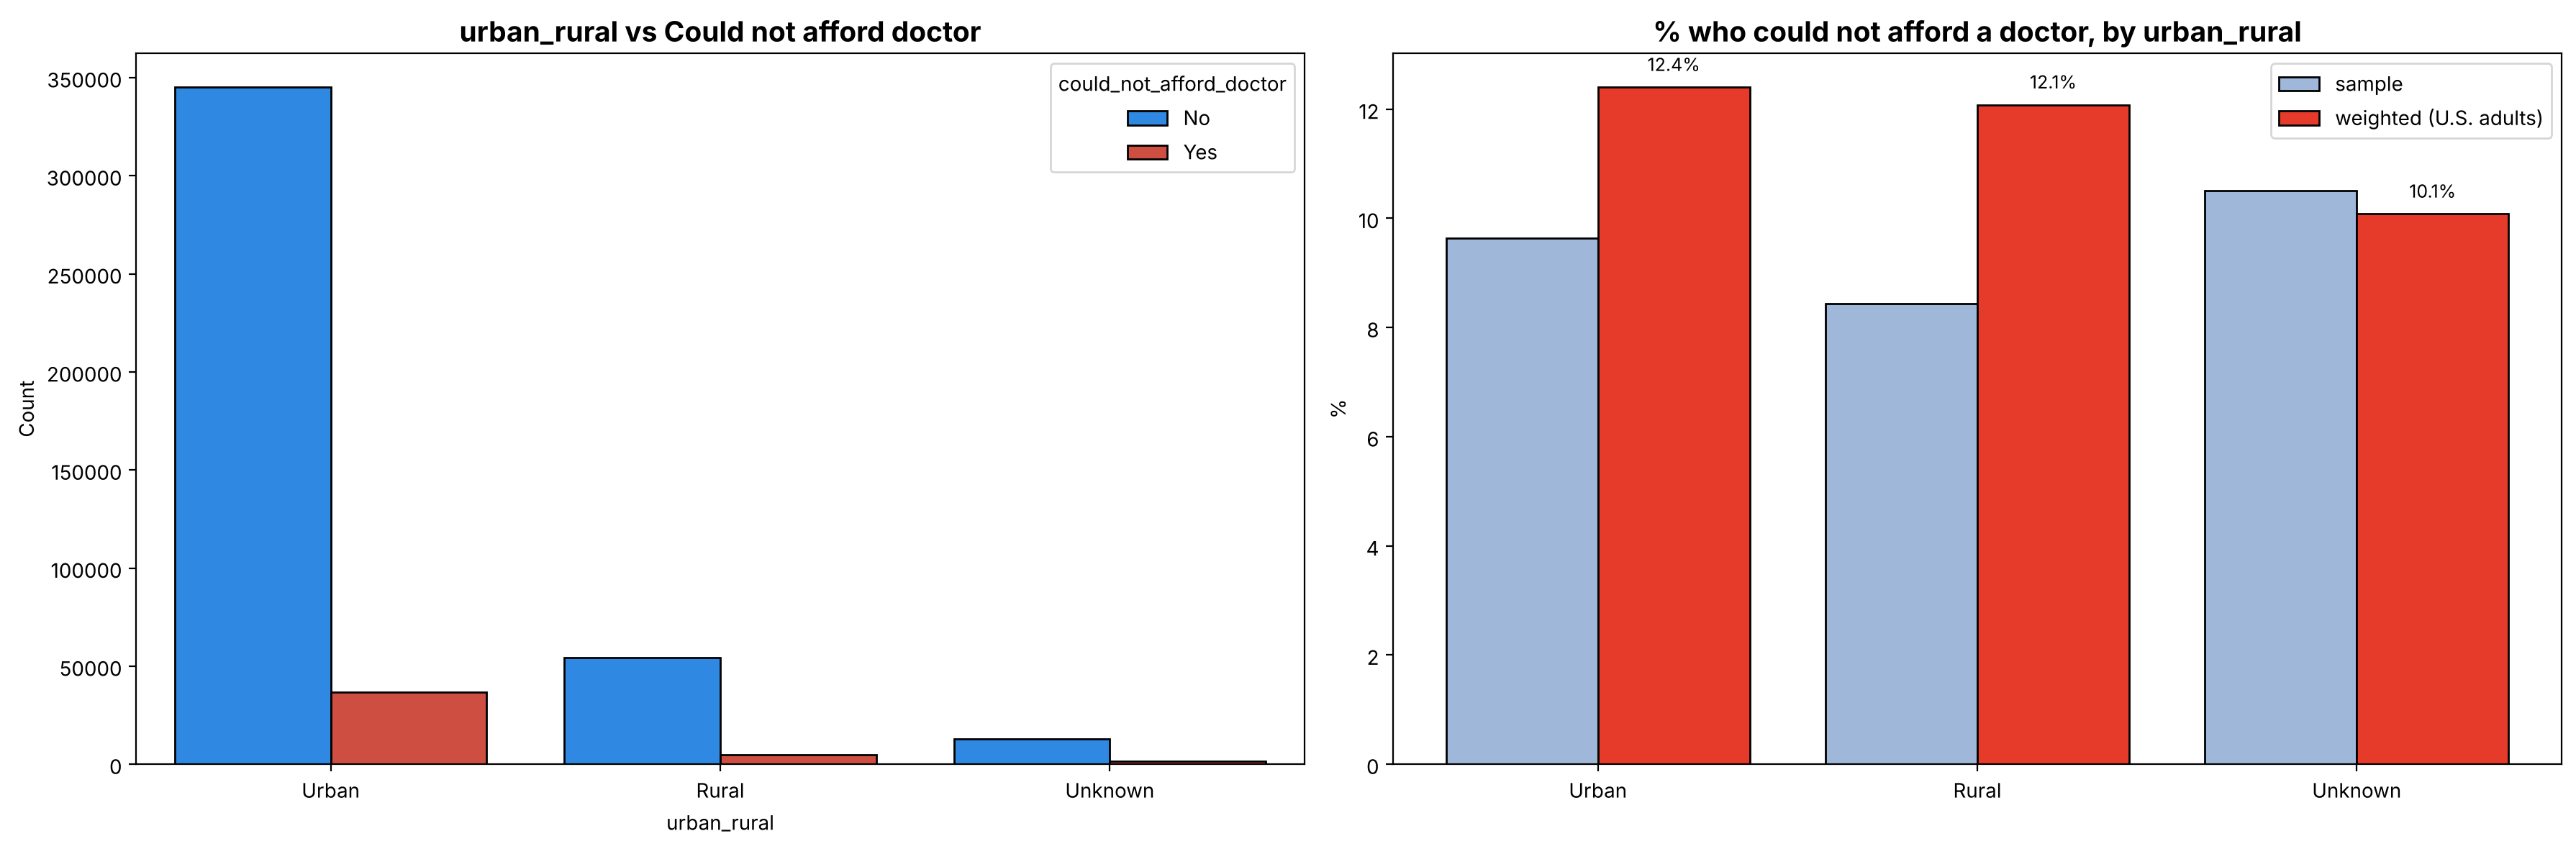

,n,% Yes (sample),% Yes (weighted)
urban_rural,,,
Urban,381858,9.64,12.40
Rural,59559,8.44,12.08
Unknown,14580,10.51,10.08


In [22]:
plot_factor('urban_rural', order=['Urban','Rural','Unknown'], rotate=0)

**Report**
* Almost **no difference**: Urban 12.4% vs Rural 12.1% (weighted). Cramér's V = 0.015.
* The urban/rural split by itself does not separate cost barriers. It is still kept, because notebook 2 checks model fairness for rural residents.

### 10.9 Does general health have any impact?

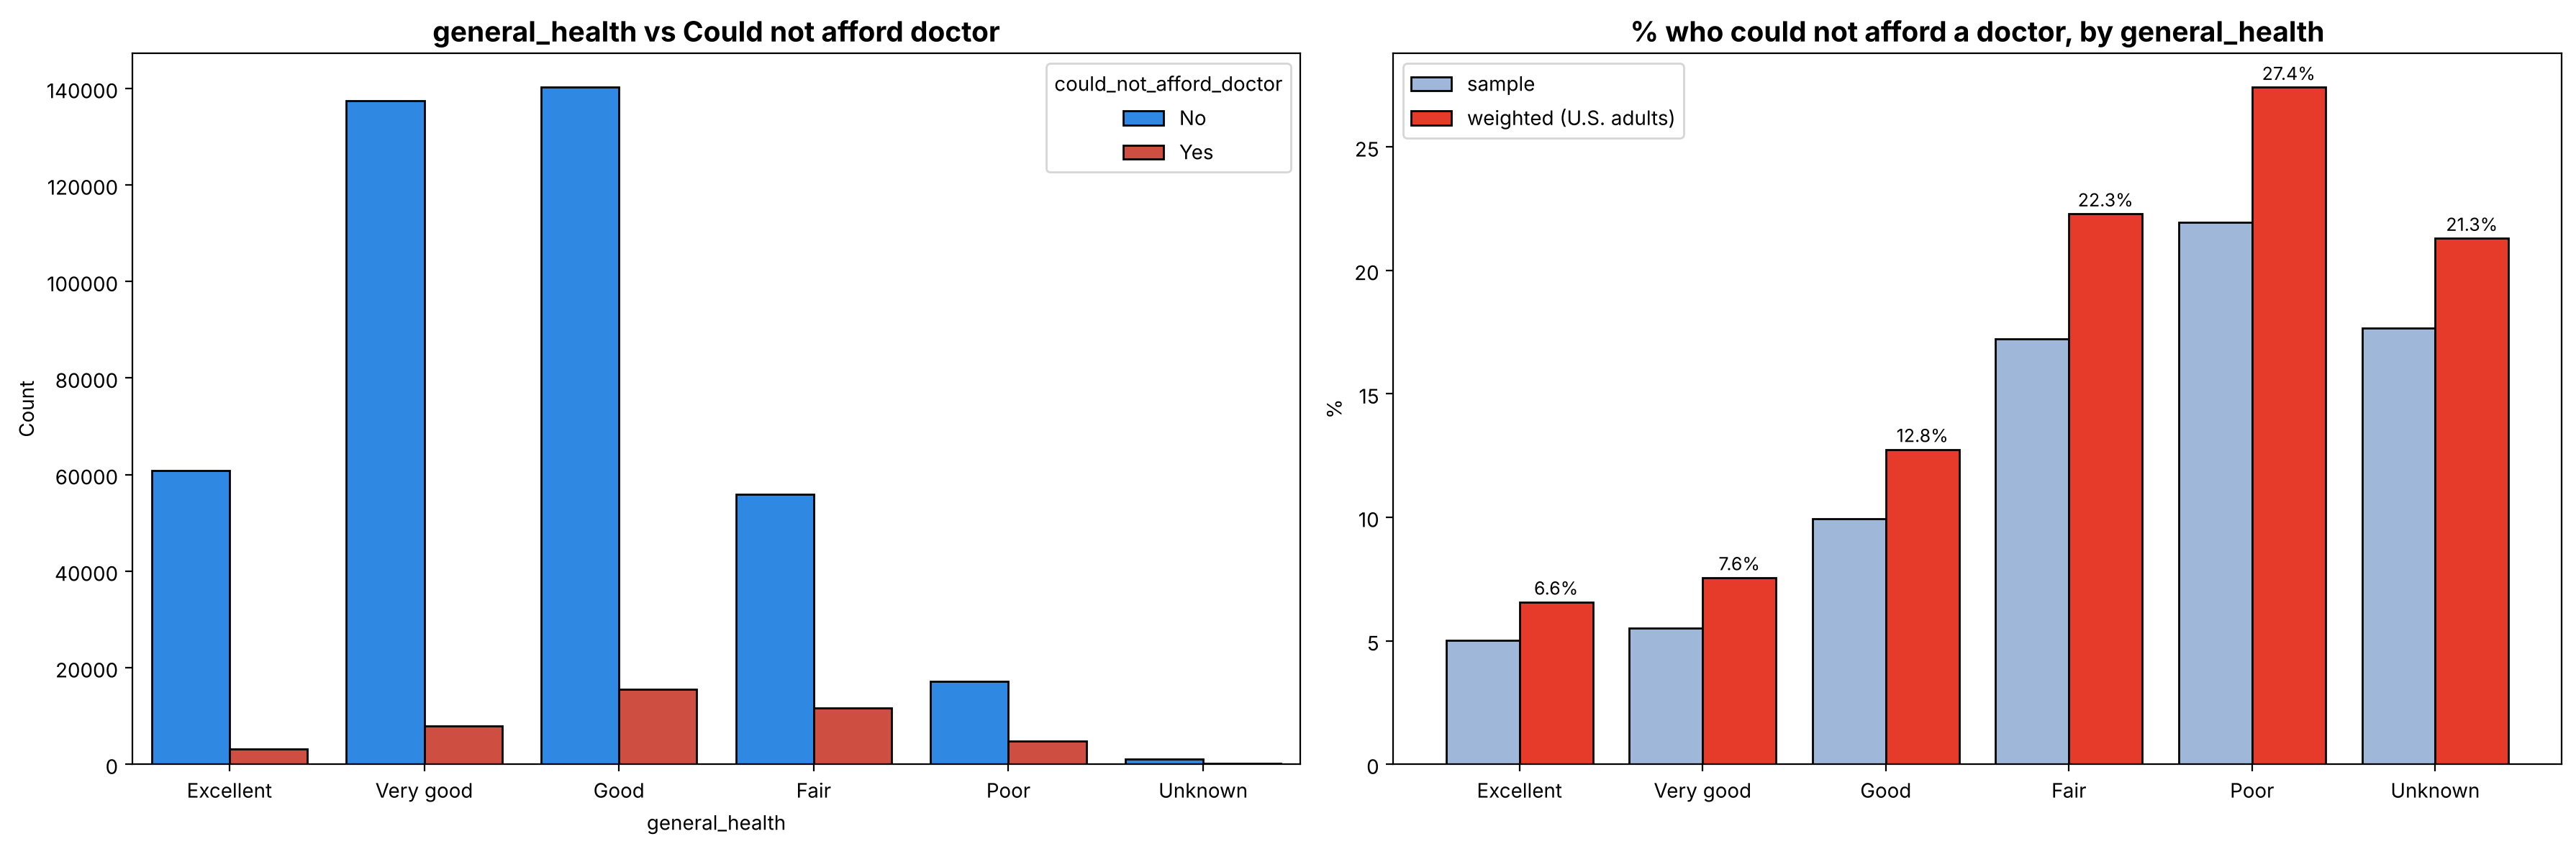

,n,% Yes (sample),% Yes (weighted)
general_health,,,
Excellent,64027,5.02,6.57
Very good,145487,5.50,7.56
Good,155697,9.94,12.75
Fair,67551,17.21,22.29
Poor,21994,21.94,27.41
Unknown,1241,17.65,21.30


In [23]:
plot_factor('general_health', order=['Excellent','Very good','Good','Fair','Poor','Unknown'], rotate=0)

**Report**
* The rate rises steadily with worse self-rated health: **Excellent 6.6% → Poor 27.4%** (weighted).
* People with the greatest health needs report the most cost barriers.

### 10.10 Does poor mental health have any impact?

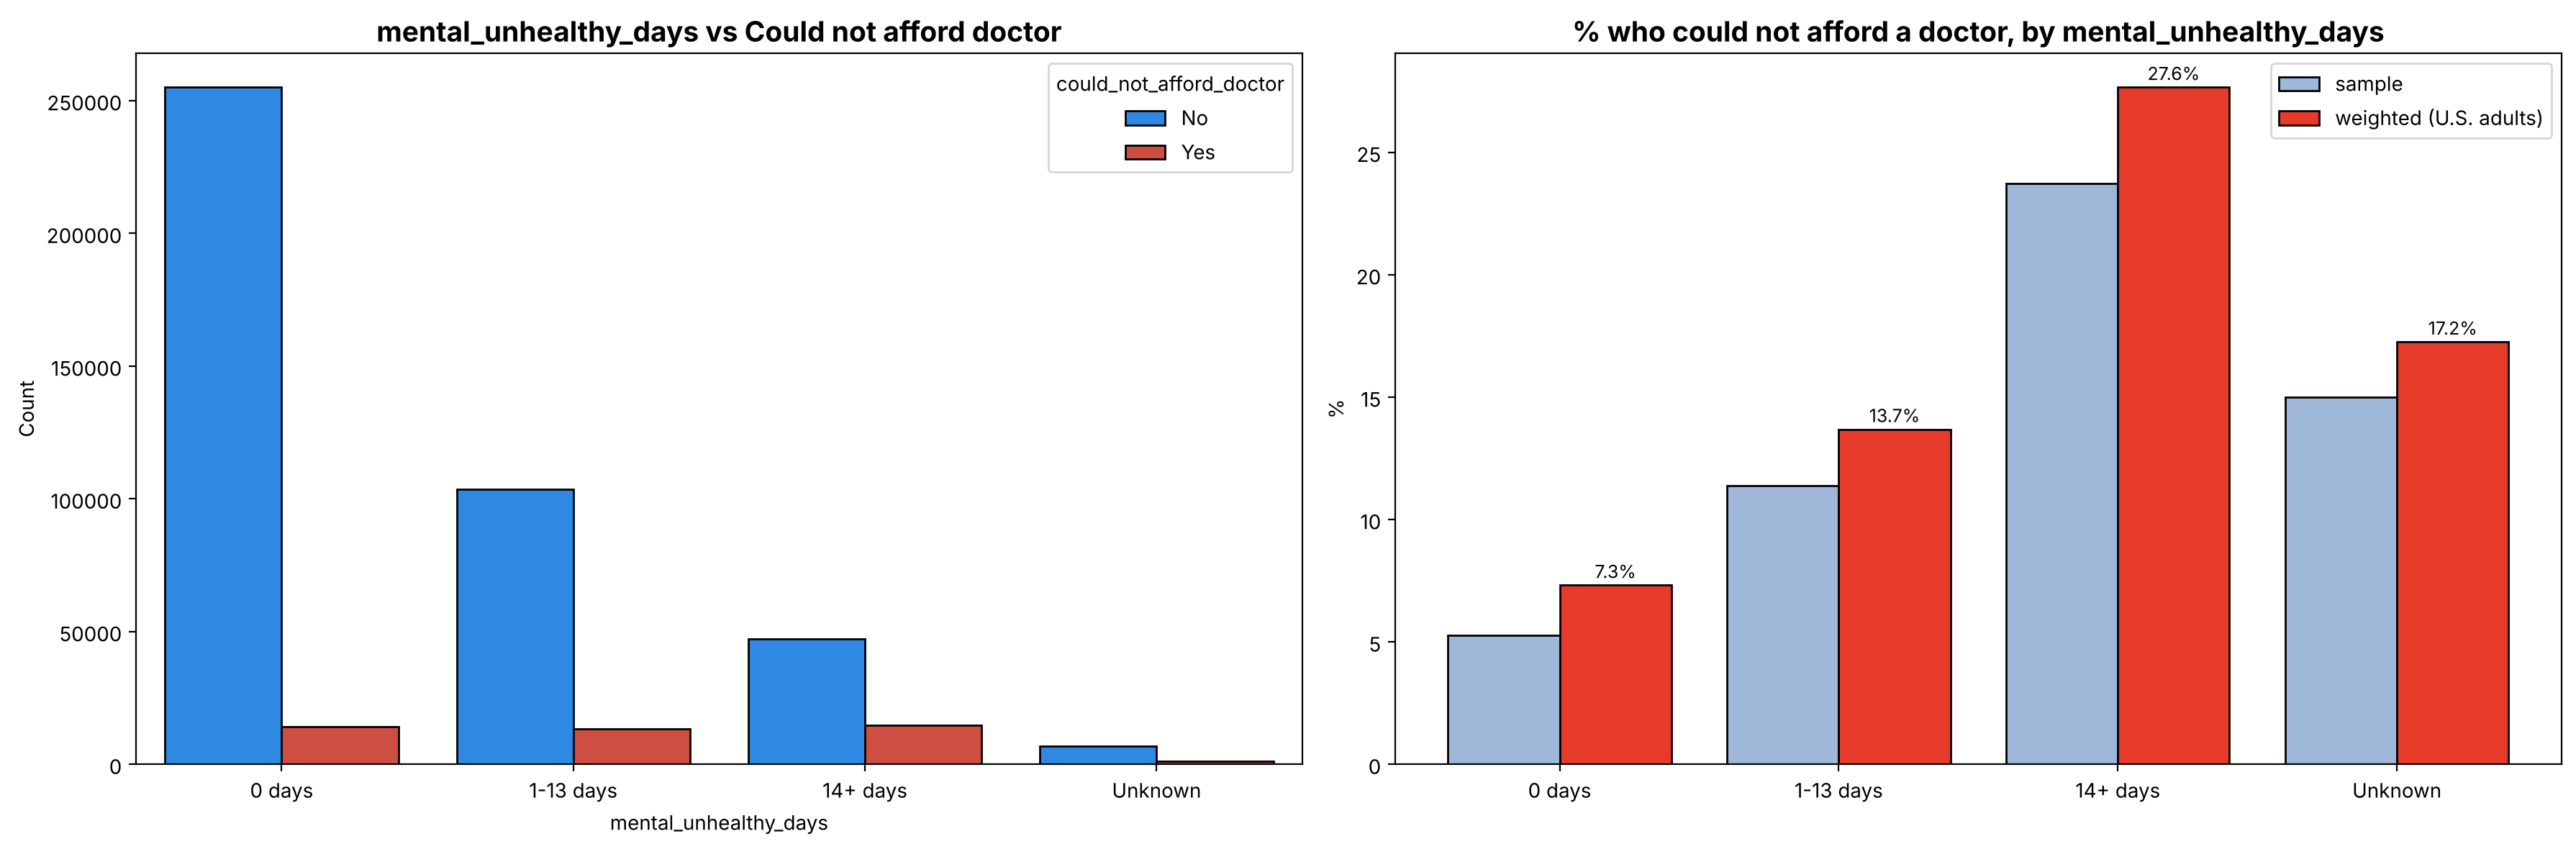

,n,% Yes (sample),% Yes (weighted)
mental_unhealthy_days,,,
0 days,269148,5.26,7.31
1-13 days,116991,11.38,13.68
14+ days,61973,23.73,27.65
Unknown,7885,14.99,17.25


In [24]:
plot_factor('mental_unhealthy_days', order=['0 days','1-13 days','14+ days','Unknown'], rotate=0)

**Report**
* **14+ poor-mental-health days: 27.7%** vs **0 days: 7.3%** (weighted), nearly 4×.
* This is the 2nd-strongest feature by Cramér's V (0.21).

### 10.11 Does sex have any impact?

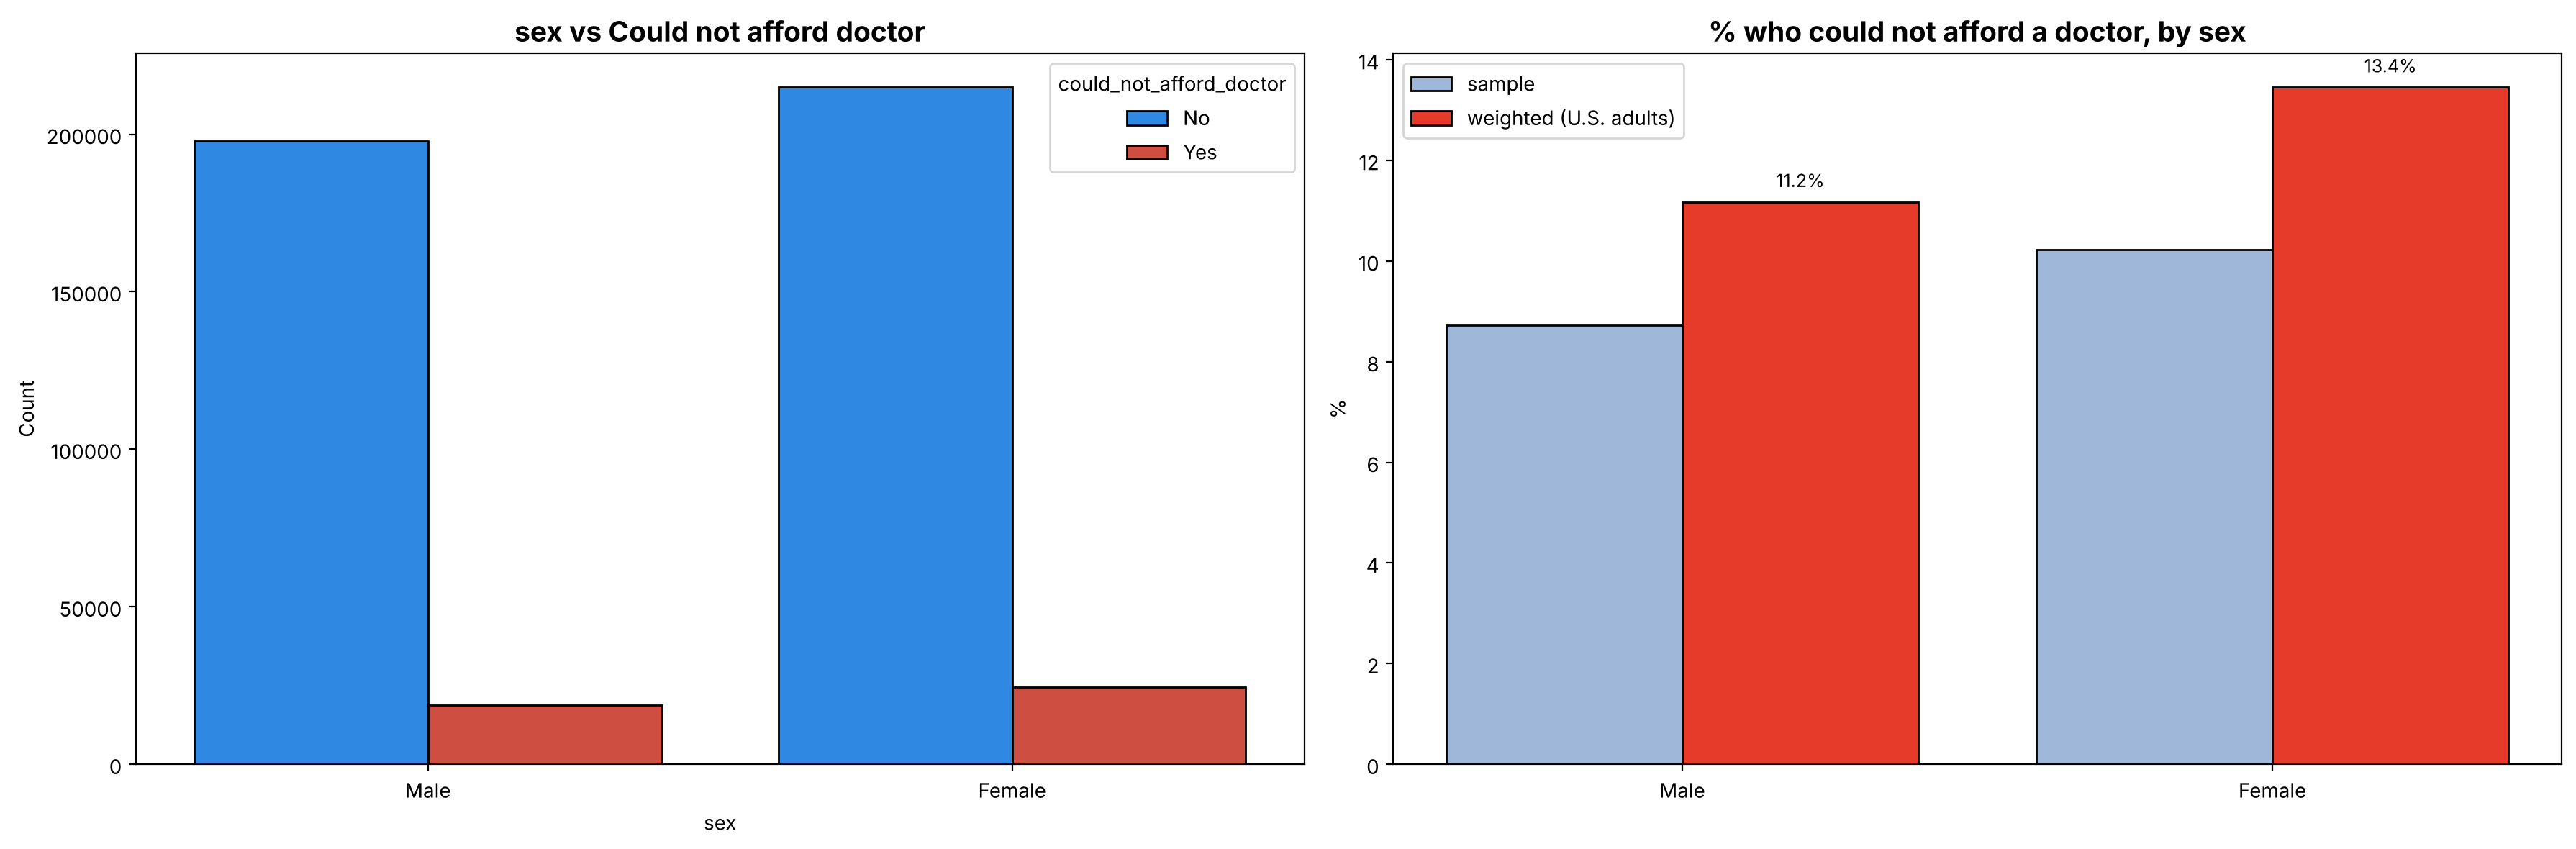

,n,% Yes (sample),% Yes (weighted)
sex,,,
Male,216632,8.72,11.17
Female,239365,10.23,13.45


In [25]:
plot_factor('sex', order=['Male','Female'], rotate=0)

**Report**
* Female 13.5% vs Male 11.2% (weighted): a small difference (Cramér's V = 0.026).

### 10.12 Do children in the household have any impact?

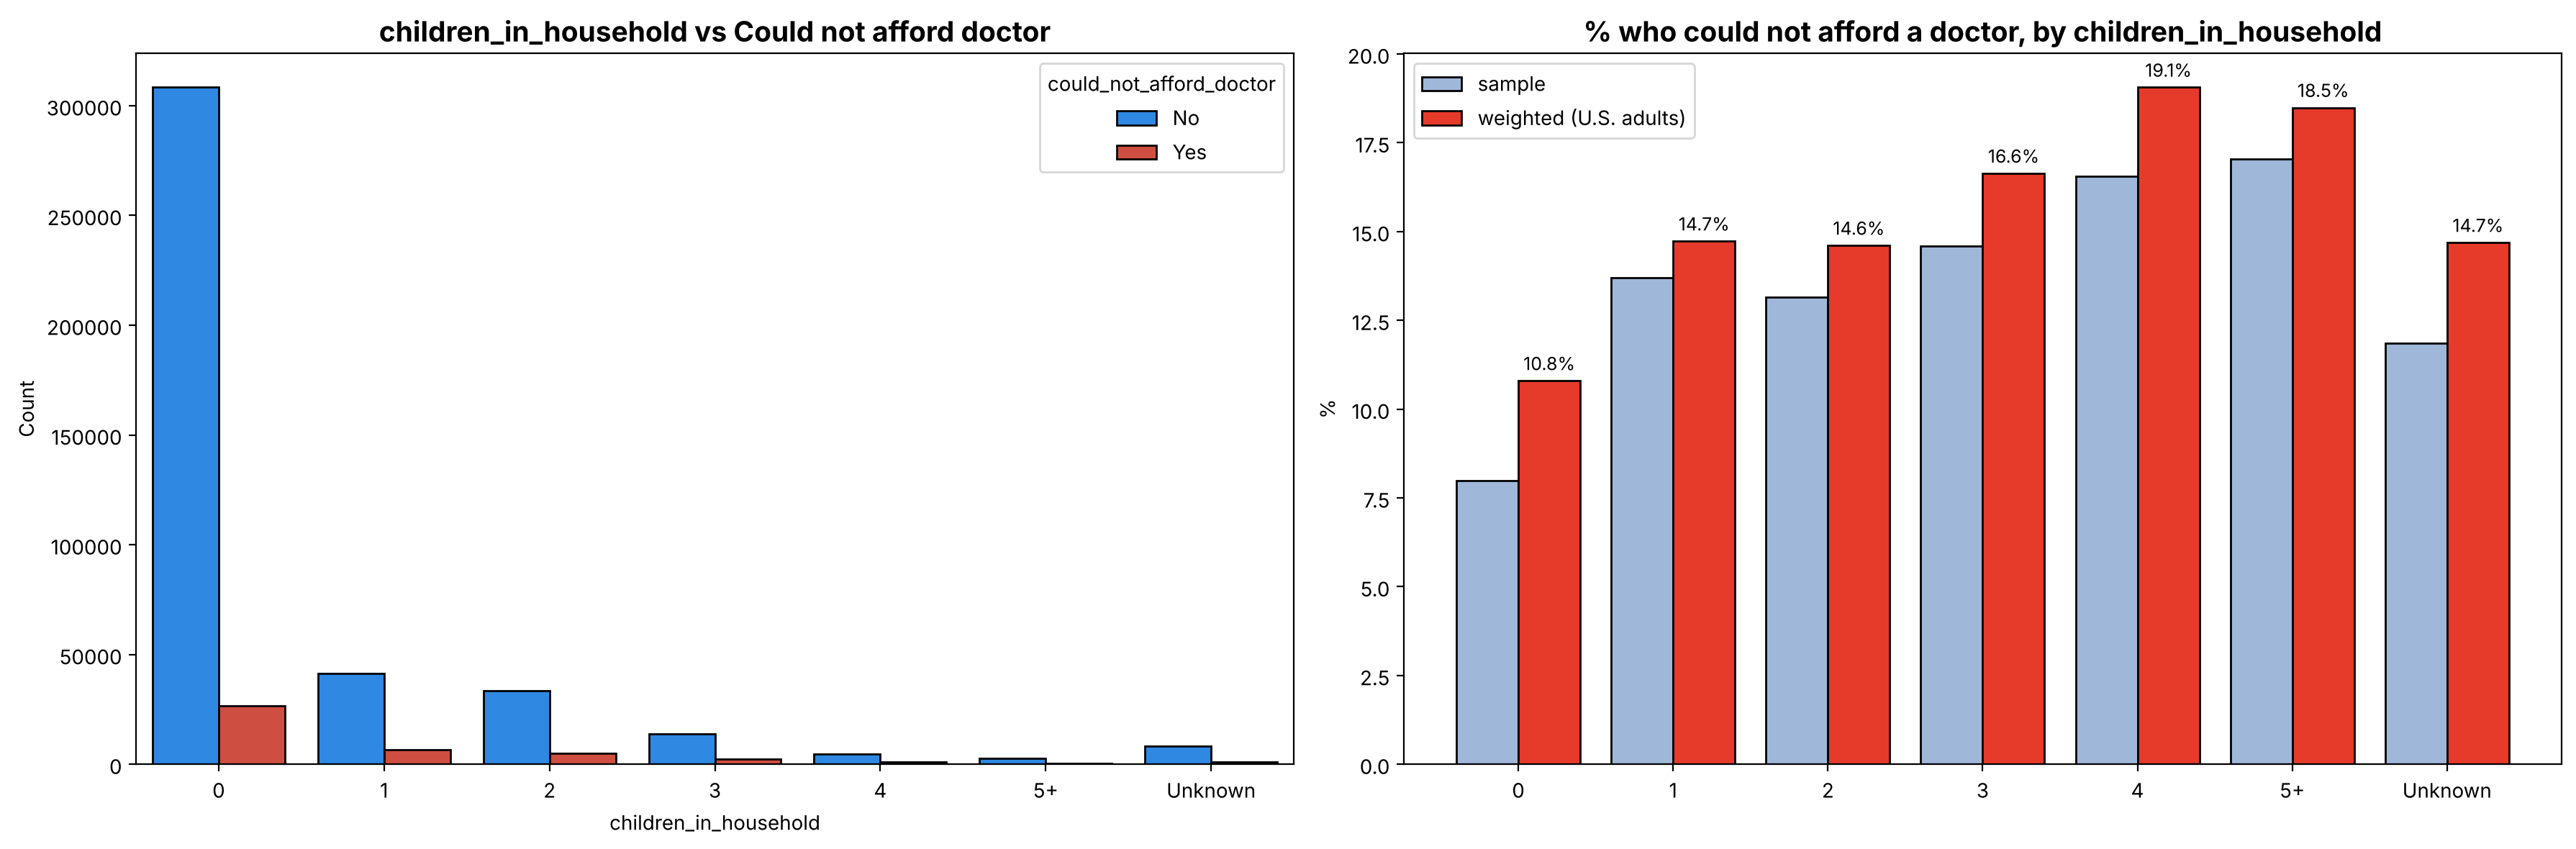

,n,% Yes (sample),% Yes (weighted)
children_in_household,,,
0,335131,7.99,10.80
1,48041,13.70,14.73
2,38719,13.16,14.61
3,16063,14.59,16.64
4,5655,16.55,19.06
5+,3132,17.05,18.49
Unknown,9256,11.86,14.69


In [26]:
plot_factor('children_in_household', order=['0','1','2','3','4','5+','Unknown'], rotate=0)

**Report**
* No children: 10.8%. With 1+ children: 14.6–19.1%, rising with the number of children (weighted).

### 10.13 Any disability (hearing, vision, cognition, mobility, self-care, independent living)

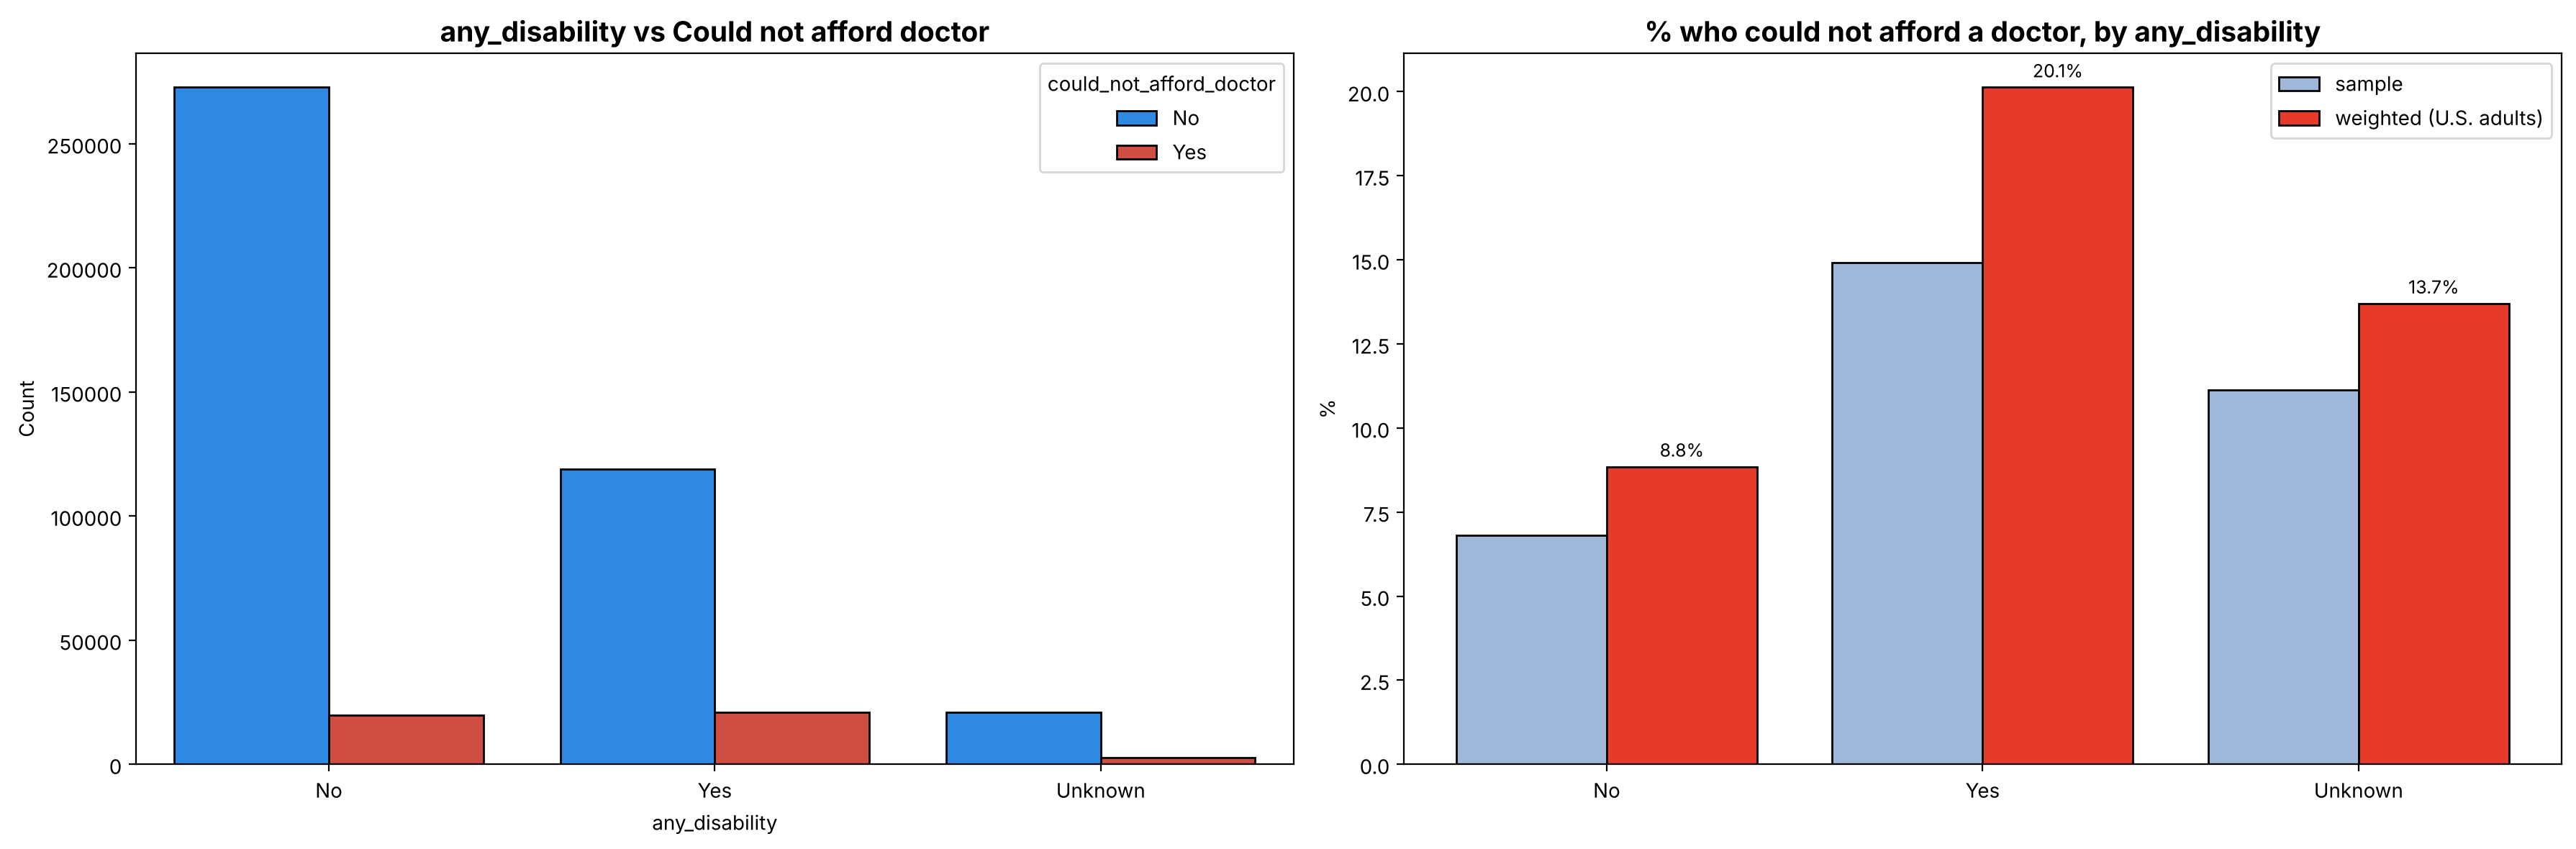

,n,% Yes (sample),% Yes (weighted)
any_disability,,,
No,292647,6.80,8.85
Yes,139722,14.91,20.13
Unknown,23628,11.13,13.70


In [27]:
dis_cols = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty',
            'selfcare_difficulty','independent_living_difficulty']
df['any_disability'] = np.where((df[dis_cols] == 'Yes').any(axis=1), 'Yes',
                        np.where((df[dis_cols] == 'No').all(axis=1), 'No', 'Unknown'))
plot_factor('any_disability', order=['No', 'Yes', 'Unknown'])

**Report**
* **Any disability: 20.1%** vs **no disability: 8.9%** (weighted), more than 2×.
* Among the individual disability types, cognitive difficulty is the most strongly associated (Cramér's V = 0.18).

# STEP 11 · State-level picture
> **What:** Weighted % by state, coloured by Medicaid-expansion status.  
> **Why here:** After person-level factors (Step 10), we look at the geographic and policy level.  
> **Result of this step:** a state ranking

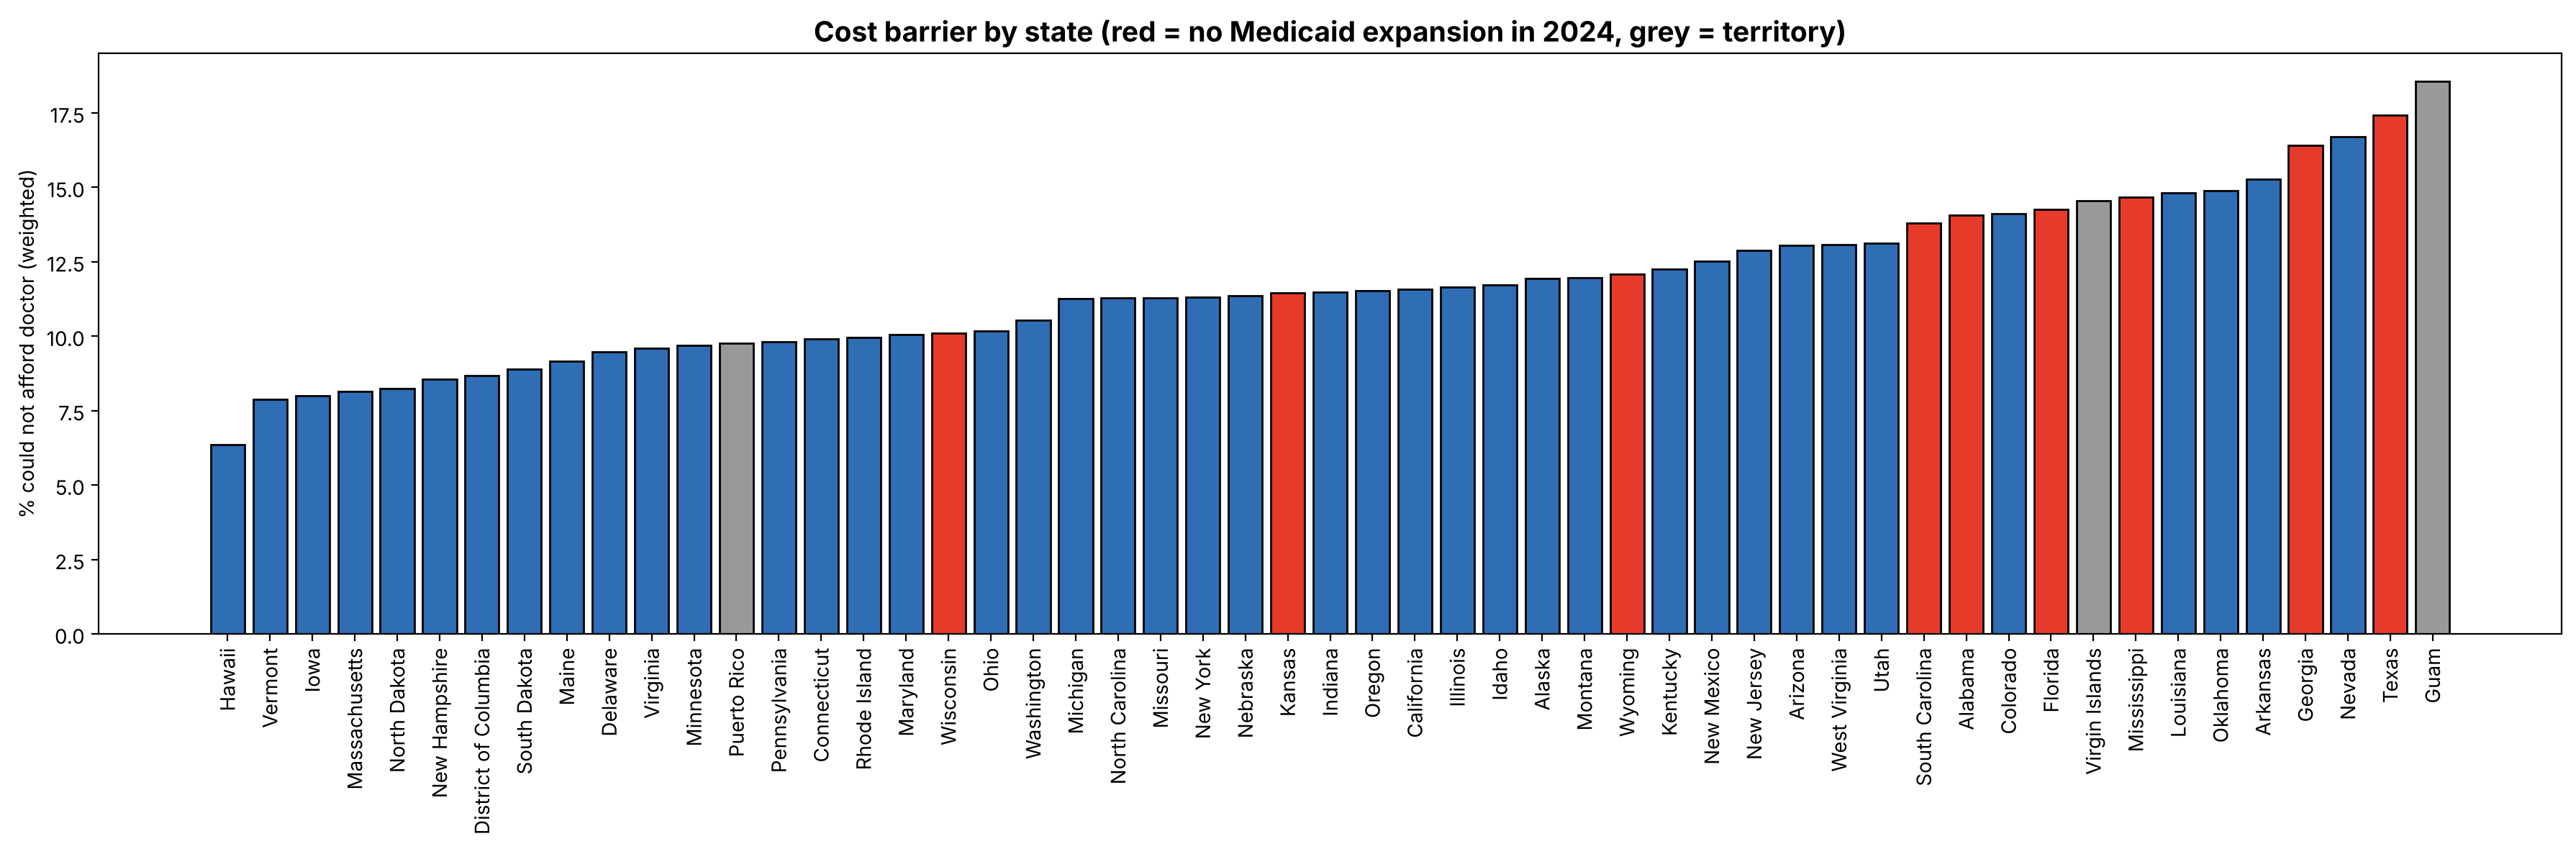

,n,% Yes (sample),% Yes (weighted),medicaid_expansion_state
state,,,,
Florida,13020,10.55,14.26,No
Virgin Islands,1341,14.17,14.55,Territory
Mississippi,2982,12.91,14.68,No
Louisiana,4523,12.67,14.81,Yes
Oklahoma,7019,12.49,14.90,Yes
Arkansas,5310,11.36,15.27,Yes
Georgia,7225,12.18,16.42,No
Nevada,2654,12.36,16.71,Yes
Texas,12252,15.08,17.44,No


In [28]:
st = target_rate_table('state').join(df.groupby('state')['medicaid_expansion_state'].first())
st = st.sort_values('% Yes (weighted)')
cmap = {'Yes': '#2f6db5', 'No': '#e63a2a', 'Territory': '#999999'}
plt.figure(figsize=(18, 6))
plt.bar(st.index, st['% Yes (weighted)'], color=st.medicaid_expansion_state.map(cmap), ec='black')
plt.xticks(rotation=90); plt.ylabel('% could not afford doctor (weighted)')
plt.title('Cost barrier by state (red = no Medicaid expansion in 2024, grey = territory)', weight='bold', fontsize=14)
plt.tight_layout(); plt.show()
st.tail(10)

**Report**
* State rates (weighted) range from about **6.4% (Hawaii)** to **17.4% (Texas)**, and Guam is highest overall (18.6%).
* Non-expansion states (red) cluster in the **upper half** (Texas, Georgia, Florida, Alabama, South Carolina, Mississippi). But Wisconsin (10.1%) is below the state median (11.5%) and Kansas sits at it (11.5%), and some expansion states (Nevada, Arkansas, Oklahoma, Louisiana) are high.
* **Expansion status alone does not explain state differences.** State composition (income, age, insurance mix) matters too, and that is what a multivariable model can sort out.

# STEP 12 · Interaction: insurance × income
> **What:** A heat map of the weighted % for each insurance-and-income combination.  
> **Why here:** Steps 10.1 and 10.2 found that insurance and income both matter. Here we check whether they work *together*.  
> **Result of this step:** a heat map

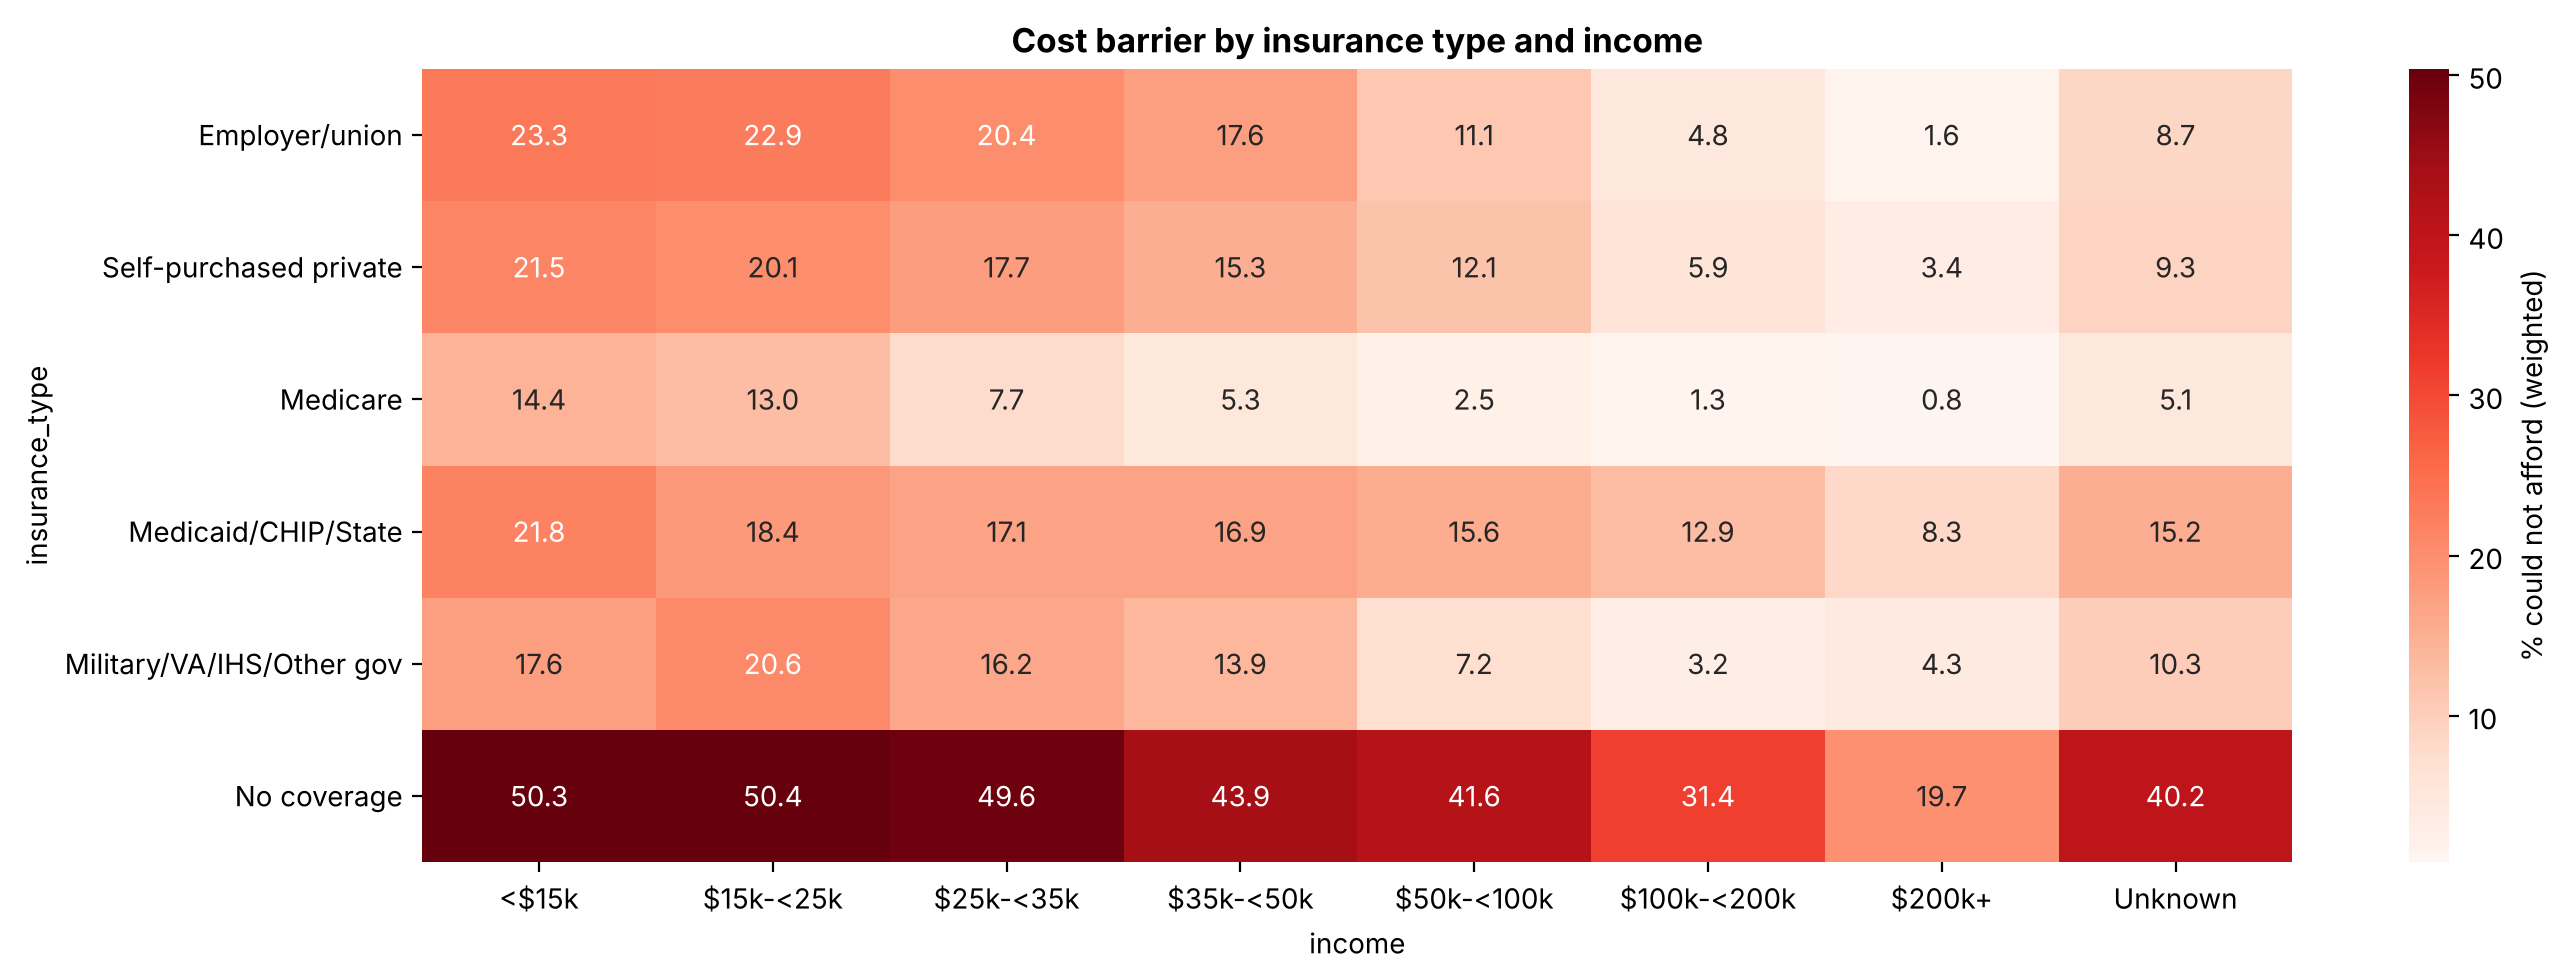

In [29]:
inc_order = ['<$15k','$15k-<25k','$25k-<35k','$35k-<50k','$50k-<100k','$100k-<200k','$200k+','Unknown']
ins_order = ['Employer/union','Self-purchased private','Medicare','Medicaid/CHIP/State','Military/VA/IHS/Other gov','No coverage']
piv = (df[df.insurance_type != 'Unknown']
       .assign(yes_w=lambda d: (d.could_not_afford_doctor == 'Yes') * d.survey_weight)
       .groupby(['insurance_type', 'income'])[['yes_w', 'survey_weight']].sum())
piv = (piv.yes_w / piv.survey_weight * 100).unstack().reindex(index=ins_order, columns=inc_order)
plt.figure(figsize=(14, 5))
sns.heatmap(piv, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '% could not afford (weighted)'})
plt.title('Cost barrier by insurance type and income', weight='bold'); plt.tight_layout(); plt.show()

**Report**
* **No coverage** is the worst at **every** income level. Even at $100k–<200k, 31.4% of uninsured adults could not afford a doctor.
* Among the insured, low income still matters: employer-insured adults under $15k report **23.3%**, versus 1.6% at $200k+.
* **Medicaid's rate is relatively flat across income** (21.8% → 8.3%), unlike the steep gradient for private coverage.
* Takeaway: insurance and income **interact**, which is a reason to use tree-based models (they capture interactions automatically) alongside logistic regression.

# STEP 13 · Final report: what we learned and what goes into the model
> **What:** Summarise the findings and the decisions passed on to the feature engineering notebook.  
> **Why here:** All analysis is done.  
> **Result of this step:** the list of decisions used in notebook 2

* **Target:** 9.5% Yes (sample), **12.3% Yes (U.S. adults, weighted)**. It is imbalanced, so accuracy alone is misleading, and imbalance handling plus PR-AUC/recall are needed.
* **Strongest factors (Cramér's V):** insurance type (0.30), mental unhealthy days (0.21), age (0.19), employment (0.19), home ownership (0.19), cognitive difficulty (0.18), general health (0.17), income (0.17).
* **Weak or negligible on their own:** urban/rural, Medicaid expansion status, sex and most individual chronic conditions. They are kept for the fairness analysis and because they may matter in combination.
* **Leakage risk:** `has_personal_doctor` and `last_checkup` measure access to care themselves, so they are **excluded** from the main model.
* **Design columns** (`seqno`, `survey_weight`, `strata`, `psu`) are not features. `state` is summarised by `census_region` + `medicaid_expansion_state`.
* **No continuous features**, so the visa notebook's power transform isn't needed. Notebook 2 adds two engineered counts (chronic conditions, disabilities).
* `Unknown` is kept as a category. Income has 19% Unknown.

########################-------------Feature Engineering and Model Training in Next ipynb------------###########################